# 객체탐지-2_학습 · 평가 · 오류분석

**이 권이 답하는 질문** · 사전학습 탐지 모델을 내 클래스에 맞게 바꿔 학습하고 평가하려면?

객체인식 Day02 강의(D2-0 ~ D2-11)와 Faster R-CNN 노트북(헤드 교체 · collate_fn · 학습 루프)을 **중복 없이 6개 대단원 · 12개 섹션**으로 재구성하고, **7장 종합 실습**(뒤집기 증강 없음 vs 있음 두 번 학습 → mAP · 클래스별 AP · 오류 유형 비교 → test 한 번)으로 연결. 강의는 HTML이라 실행 코드를 로컬(Windows · GPU) 기준으로 다시 만들었고, 학습은 **작은 부분집합(train 600 · val 200 · test 200장) · 5 epoch**로 줄임. IoU · 짝짓기 · AP 계산 원리는 **객체탐지-1 3 · 5 · 6장 참조**로 대신하고 여기서는 torchmetrics로 계산함.

## 객체탐지 3권 구성

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">권</th>
<th style="text-align: left;">묻는 질문</th>
<th style="text-align: left;">재료</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">객체탐지-1 박스 · IoU · NMS · 채점</td>
<td style="text-align: left;">사진 속 "무엇이 · 어디에"를 숫자로 어떻게 표현하고, 맞았는지 어떻게 채점하나?</td>
<td style="text-align: left;">Day01 + 평가지표 보충</td>
</tr>
<tr>
<td style="text-align: left;"><strong>객체탐지-2</strong> 우리 데이터로 학습 · 평가 (이 권)</td>
<td style="text-align: left;">사전학습 탐지 모델을 내 클래스에 맞게 바꿔 학습하고 평가하려면?</td>
<td style="text-align: left;">Day02 + Faster R-CNN 노트북</td>
</tr>
<tr>
<td style="text-align: left;">객체탐지-3 모델 계열 비교 · YOLO 실전</td>
<td style="text-align: left;">2단계 · 1단계 모델은 무엇이 다르고, 프로젝트에서는 무엇을 쓰나?</td>
<td style="text-align: left;">Day01 D1-7 · D1-8 · D1-10 + 객체인식 PDF + ultralytics</td>
</tr>
</tbody>
</table>

## 이 노트북을 끝내면 답할 수 있어야 하는 질문

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">대단원</th>
<th style="text-align: left;">질문</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><strong>1. 나누기 · Dataset · collate_fn</strong></td>
<td style="text-align: left;">정답 있는 사진을 어떻게 나누고, 크기 · 박스 수가 다른 사진을 어떻게 묶는가?</td>
</tr>
<tr>
<td style="text-align: left;"><strong>2. 박스 증강</strong></td>
<td style="text-align: left;">사진을 뒤집을 때 박스는 어떻게 따라가게 하는가?</td>
</tr>
<tr>
<td style="text-align: left;"><strong>3. 헤드 교체</strong></td>
<td style="text-align: left;">COCO 91칸 모델을 내 클래스 수로 바꾸려면 어느 층을 어떻게 바꾸는가?</td>
</tr>
<tr>
<td style="text-align: left;"><strong>4. 스모크 테스트</strong></td>
<td style="text-align: left;">긴 학습 전 1분 안에 무엇을 확인하고, 모드마다 출력은 어떻게 다른가?</td>
</tr>
<tr>
<td style="text-align: left;"><strong>5. 학습 · 체크포인트</strong></td>
<td style="text-align: left;">학습 루프 · lr 스케줄러 · last · best 체크포인트는 어떻게 다루는가?</td>
</tr>
<tr>
<td style="text-align: left;"><strong>6. 평가 · 오류 분석</strong></td>
<td style="text-align: left;">학습 효과를 어떻게 재고, 남은 오류는 어디서 나오는가?</td>
</tr>
<tr>
<td style="text-align: left;"><strong>7. 종합 실습</strong></td>
<td style="text-align: left;">증강 하나만 바꾼 두 학습 중 무엇이 나으며, 그렇게 말할 수 있는가?</td>
</tr>
</tbody>
</table>

## 읽는 법

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">표시</th>
<th style="text-align: left;">의미</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>A</code> · <code>B</code></td>
<td style="text-align: left;"><strong>A</strong> 딥러닝 코드에 바로 나오는 필수 · <strong>B</strong> 알아두면 되는 것</td>
</tr>
<tr>
<td style="text-align: left;">🎯</td>
<td style="text-align: left;">이번 섹션에서 답해야 할 질문</td>
</tr>
<tr>
<td style="text-align: left;">💡</td>
<td style="text-align: left;">쉬운 설명 · 비유</td>
</tr>
<tr>
<td style="text-align: left;">⚠️</td>
<td style="text-align: left;">자주 하는 실수</td>
</tr>
<tr>
<td style="text-align: left;">✅</td>
<td style="text-align: left;">기억할 결론 = 🎯 질문의 답</td>
</tr>
</tbody>
</table>

**섹션 구성** · 🎯 질문 → 💡 쉬운 설명 → 실행 흐름 → 먼저 예측 → 코드 → 예측 정답 · 결과 해설 → 차이 · 언제 쓰나 → ⚠️ 주의 → ✅ 한 줄 정리

**코드 주석** · 코드 위 = 이 단계에서 하는 일, 코드 옆 = 실행 흐름 · 문법 구조

**그림 색** · 초록 = 정답(XML) · 파랑 = 예측 · 빨강 = 잘못된 박스

### 원본 → 섹션 대응표

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">원본</th>
<th style="text-align: left;">내용</th>
<th style="text-align: left;">섹션</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">Day02 D2-0 · D2-1</td>
<td style="text-align: left;">할 일 · train · val · held-out test 나누기</td>
<td style="text-align: left;">1-1 (사진 수를 줄인 부분집합)</td>
</tr>
<tr>
<td style="text-align: left;">Day02 D2-2</td>
<td style="text-align: left;">Dataset · collate_fn · 첫 batch 점검 · train EDA</td>
<td style="text-align: left;">1-2 · 1-3 (얼굴 크기 EDA는 6-2 크기별 분석으로 <strong>통합</strong>)</td>
</tr>
<tr>
<td style="text-align: left;">Day02 D2-3</td>
<td style="text-align: left;">박스를 따라가는 좌우 뒤집기</td>
<td style="text-align: left;">2-1 (상하 · 회전은 비교표로)</td>
</tr>
<tr>
<td style="text-align: left;">Day02 D2-4</td>
<td style="text-align: left;">미션 헤드 91칸 → 3칸</td>
<td style="text-align: left;">3-1</td>
</tr>
<tr>
<td style="text-align: left;">Faster R-CNN 노트북</td>
<td style="text-align: left;">collate_fn · 헤드 교체 · 학습 루프</td>
<td style="text-align: left;">1-3 · 3-2 · 5-1 (VGG 직접 조립 · Colab · COCO 다운로드 코드는 제외)</td>
</tr>
<tr>
<td style="text-align: left;">Day02 D2-5</td>
<td style="text-align: left;">스모크 테스트 · 모드별 출력</td>
<td style="text-align: left;">4-1 · 4-2</td>
</tr>
<tr>
<td style="text-align: left;">Day02 D2-6</td>
<td style="text-align: left;">학습 · scheduler 버그 · last vs best · 다시 불러오기 · 이어 학습</td>
<td style="text-align: left;">5-1 · 5-2 (강의는 미리 학습한 기록을 읽음 → 여기서는 직접 학습)</td>
</tr>
<tr>
<td style="text-align: left;">Day02 D2-7 · D2-8</td>
<td style="text-align: left;">예측 · 집계 · AP · mAP</td>
<td style="text-align: left;">6-1 (계산 원리는 객체탐지-1 5 · 6장 <strong>참조</strong>)</td>
</tr>
<tr>
<td style="text-align: left;">Day02 D2-9</td>
<td style="text-align: left;">오류 분석</td>
<td style="text-align: left;">6-2</td>
</tr>
<tr>
<td style="text-align: left;">Day02 D2-10 · D2-11</td>
<td style="text-align: left;">하나만 바꾸기 · 최종 모델 고르기 · test 한 번</td>
<td style="text-align: left;">7장</td>
</tr>
<tr>
<td style="text-align: left;">미션 7 · SSD · Faster R-CNN 직접 구현</td>
<td style="text-align: left;">—</td>
<td style="text-align: left;">제외</td>
</tr>
</tbody>
</table>

강의의 Mac(MPS) · Colab(`/content`, `!pip`) 경로는 로컬 Windows 기준으로 바꿈. 체크포인트 설명 중 이미지분류와 겹치는 일반 내용은 넣지 않고 탐지에서 달라지는 점(last · best 내용물, 이어 학습)만 다룸.

## 전체 지도

### 단원 연결 · 왜 이 순서로 배우는가

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: center;">순서</th>
<th style="text-align: left;">배우는 이유</th>
<th style="text-align: left;">대단원</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: center;">1</td>
<td style="text-align: left;">학습 · 고르기 · 채점용 사진을 나누고, 모델이 받는 묶음을 만든다</td>
<td style="text-align: left;">나누기 · Dataset · collate_fn</td>
</tr>
<tr>
<td style="text-align: center;">2</td>
<td style="text-align: left;">데이터를 늘리는 증강도 박스까지 함께 바꿔야 정답이 유지된다</td>
<td style="text-align: left;">박스 증강</td>
</tr>
<tr>
<td style="text-align: center;">3</td>
<td style="text-align: left;">COCO 91칸 모델을 우리 3칸으로 바꾼다</td>
<td style="text-align: left;">헤드 교체</td>
</tr>
<tr>
<td style="text-align: center;">4</td>
<td style="text-align: left;">긴 학습 전에 연결 실수를 1분 안에 잡는다</td>
<td style="text-align: left;">스모크 테스트</td>
</tr>
<tr>
<td style="text-align: center;">5</td>
<td style="text-align: left;">학습하고, 좋은 epoch를 val로 골라 저장한다</td>
<td style="text-align: left;">학습 · 체크포인트</td>
</tr>
<tr>
<td style="text-align: center;">6</td>
<td style="text-align: left;">학습 효과를 재고 남은 오류를 종류별로 본다</td>
<td style="text-align: left;">평가 · 오류 분석</td>
</tr>
<tr>
<td style="text-align: center;">7</td>
<td style="text-align: left;">하나만 바꾼 두 학습을 비교하고 test로 한 번 채점한다</td>
<td style="text-align: left;">종합 실습</td>
</tr>
</tbody>
</table>

### ML/DL 공통 파이프라인 · 각 대단원이 쓰이는 곳

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">단계</th>
<th style="text-align: left;">하는 일</th>
<th style="text-align: left;">쓰이는 장</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">① 데이터 준비</td>
<td style="text-align: left;">정답 있는 사진 · train · val · test 나누기</td>
<td style="text-align: left;">1장</td>
</tr>
<tr>
<td style="text-align: left;">② 불러오기</td>
<td style="text-align: left;">탐지 Dataset · collate_fn · DataLoader</td>
<td style="text-align: left;">1장</td>
</tr>
<tr>
<td style="text-align: left;">③ 전처리</td>
<td style="text-align: left;">사진과 박스를 함께 뒤집는 증강</td>
<td style="text-align: left;">2장</td>
</tr>
<tr>
<td style="text-align: left;">④ 모델</td>
<td style="text-align: left;">사전학습 SSD · Faster R-CNN의 헤드 교체</td>
<td style="text-align: left;">3장</td>
</tr>
<tr>
<td style="text-align: left;">⑤ 학습</td>
<td style="text-align: left;">스모크 테스트 → 학습 루프 · scheduler</td>
<td style="text-align: left;"><strong>4장 · 5장</strong></td>
</tr>
<tr>
<td style="text-align: left;">⑥ 평가</td>
<td style="text-align: left;">val mAP · 클래스별 AP · 오류 분석 · test 한 번</td>
<td style="text-align: left;"><strong>6장 · 7장</strong></td>
</tr>
<tr>
<td style="text-align: left;">⑦ 저장 · 기록</td>
<td style="text-align: left;">last · best 체크포인트 · 결과 한 문장</td>
<td style="text-align: left;">5장 · 7장</td>
</tr>
</tbody>
</table>

**굵은 장** · 이 권의 중심은 ⑤ 학습과 ⑥ 평가 — 객체탐지-1의 채점 방법을 학습한 모델에 적용

---
## 0. 준비

라이브러리 · 설정 · 데이터 경로 · 정답 읽기와 그림 도우미를 준비함. **셀은 위에서부터 차례로 실행**(앞 섹션의 변수 · 함수를 이어서 씀).

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">설정</th>
<th style="text-align: left;">내용</th>
<th style="text-align: left;">이유</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>torch.manual_seed(0)</code> · <code>cudnn.deterministic</code></td>
<td style="text-align: left;">난수 · cuDNN 연산 고정</td>
<td style="text-align: left;">같은 설정으로 다시 학습해도 같은 값 (두 번 실행해 확인)</td>
</tr>
<tr>
<td style="text-align: left;"><code>DataLoader(generator=seed 0)</code> · 뒤집기 전용 <code>Generator(seed 1)</code></td>
<td style="text-align: left;">섞는 순서 · 뒤집기 난수 고정</td>
<td style="text-align: left;">RUN_A · RUN_B가 증강 하나만 다르게</td>
</tr>
<tr>
<td style="text-align: left;"><code>device</code></td>
<td style="text-align: left;">GPU가 있으면 <code>cuda</code>, 없으면 <code>cpu</code></td>
<td style="text-align: left;">코드 수정 없이 실행 (CPU는 학습이 매우 느림 · 수 시간)</td>
</tr>
<tr>
<td style="text-align: left;"><code>CKPT_DIR</code></td>
<td style="text-align: left;">노트북 옆 <code>checkpoints_객체탐지-2/</code></td>
<td style="text-align: left;">체크포인트 4개(약 0.6GB) · GitHub에는 안 올림</td>
</tr>
<tr>
<td style="text-align: left;"><code>KMP_DUPLICATE_LIB_OK</code></td>
<td style="text-align: left;">OpenMP 중복 허용</td>
<td style="text-align: left;">Windows Anaconda에서 커널이 죽는 문제 방지 (객체탐지-1과 같음)</td>
</tr>
</tbody>
</table>

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">데이터 · 모델</th>
<th style="text-align: left;">내용</th>
<th style="text-align: left;">처음 나오는 곳</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>train_ids</code> · <code>val_ids</code> · <code>test_ids</code></td>
<td style="text-align: left;">정답 있는 사진 600 · 200 · 200장 (품종 층화)</td>
<td style="text-align: left;">1-1</td>
</tr>
<tr>
<td style="text-align: left;"><code>PetFaces</code> · <code>train_loader</code></td>
<td style="text-align: left;">탐지 Dataset · 16장씩 묶는 DataLoader</td>
<td style="text-align: left;">1-2 · 1-3</td>
</tr>
<tr>
<td style="text-align: left;"><code>make_ssd()</code></td>
<td style="text-align: left;">COCO SSD300 + 3칸 분류 헤드</td>
<td style="text-align: left;">3-1</td>
</tr>
<tr>
<td style="text-align: left;"><code>model_A</code> · <code>model_best_A</code></td>
<td style="text-align: left;">RUN_A(뒤집기 없음) 마지막 · best</td>
<td style="text-align: left;">5-1 · 5-2</td>
</tr>
<tr>
<td style="text-align: left;"><code>model_best_B</code></td>
<td style="text-align: left;">RUN_B(뒤집기 있음) best</td>
<td style="text-align: left;">7장</td>
</tr>
</tbody>
</table>

**도우미 함수** · `load_image` · `read_voc` · `make_target`(객체탐지-1 2장과 같음) · `show(사진, gt=, pred=, bad=)` 박스 그림. 처음 실행 때 SSD300 · Faster R-CNN weights를 내려받음(torch 캐시에 있으면 생략).

In [1]:
# 라이브러리 불러오기
import math  # 손실이 숫자인지 확인 (isfinite)
import os  # 환경 변수 · 파일 크기
import time  # 학습 시간 재기
import xml.etree.ElementTree as ET  # XML 정답 읽기
from collections import Counter  # 개수 세기
from pathlib import Path

import kagglehub  # Kaggle 데이터 (있으면 캐시 경로만)
import matplotlib.pyplot as plt
import torch
import torchvision
import torchvision.transforms.functional as TF  # PIL → 텐서
from matplotlib import patches  # 박스 그리기
from PIL import Image
from sklearn.model_selection import train_test_split  # 품종 비율 유지 분할
from torch.utils.data import DataLoader, Dataset
from torchmetrics.detection import MeanAveragePrecision  # mAP (객체탐지-1 6장)
from torchvision.ops import box_iou  # IoU 표 (객체탐지-1 3장)


# Windows Anaconda: numpy(MKL) · torch OpenMP 충돌 방지 (객체탐지-1 0장)
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")


# seed 고정 + cuDNN 결정적 연산 → 같은 설정으로 다시 학습해도 같은 값
torch.manual_seed(0)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False


# 실행 장치: GPU가 있으면 cuda, 없으면 cpu (코드는 그대로, CPU는 매우 느림)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
plt.rcParams["font.family"] = "Malgun Gothic"  # 그림 속 한글 (Windows)
plt.rcParams["axes.unicode_minus"] = False


# 데이터 경로 (객체탐지-1과 같은 Oxford-IIIT Pet) · 체크포인트 폴더
ROOT = Path(kagglehub.dataset_download(
    "zippyz/cats-and-dogs-breeds-classification-oxford-dataset/versions/1"))
IMAGES = ROOT / "images" / "images"
ANN = ROOT / "annotations" / "annotations"
XMLS = ANN / "xmls"
CKPT_DIR = Path("checkpoints_객체탐지-2")  # 노트북 옆 폴더 (GitHub에 안 올림)
CKPT_DIR.mkdir(exist_ok=True)
print("torch", torch.__version__.split("+")[0],
      "| torchvision", torchvision.__version__.split("+")[0],
      "| 실행 장치:", device.type)


# 정답 읽기 도우미 (객체탐지-1 2장과 같음)
CLASSES = ["배경", "고양이 얼굴", "개 얼굴"]  # 번호 0 · 1 · 2
NAME_TO_LABEL = {"cat": 1, "dog": 2}


def load_image(stem):
    return Image.open(IMAGES / f"{stem}.jpg").convert("RGB")


def read_voc(stem):
    """XML → (박스 목록 xyxy, 이름 목록)"""
    objs = list(ET.parse(XMLS / f"{stem}.xml").getroot().iter("object"))
    boxes = [[float(o.find("bndbox").findtext(k))
              for k in ("xmin", "ymin", "xmax", "ymax")] for o in objs]
    return boxes, [o.findtext("name") for o in objs]


def make_target(stem):
    """XML → {boxes [N, 4] float32, labels [N] int64} (객체탐지-1 2-5)"""
    boxes, names = read_voc(stem)
    return {"boxes": torch.tensor(boxes, dtype=torch.float32),
            "labels": torch.tensor([NAME_TO_LABEL[n] for n in names],
                                   dtype=torch.int64)}


# 그림 도우미: 정답 = 초록 · 예측 = 파랑 · 잘못된 박스 = 빨강
GT_COLOR, PRED_COLOR, BAD_COLOR = "#2e7d32", "#0277bd", "#c62828"


def show(img, gt=(), pred=(), bad=(), labels=None, title="", ax=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(5, 4))
    if torch.is_tensor(img):
        img = img.permute(1, 2, 0)  # [3, H, W] → [H, W, 3]
    ax.imshow(img)
    ax.axis("off")
    for boxes, color, lw in ((pred, PRED_COLOR, 2.5), (gt, GT_COLOR, 3),
                             (bad, BAD_COLOR, 3)):
        for i, b in enumerate(boxes):
            x1, y1, x2, y2 = [float(v) for v in b]
            ax.add_patch(patches.Rectangle(  # (왼쪽 위, 너비, 높이)
                (x1, y1), x2 - x1, y2 - y1, fill=False, ec=color, lw=lw))
            if labels and color == PRED_COLOR:
                ax.text(x1 + 3, y1 + 3, labels[i], va="top", fontsize=9,
                        color="white", bbox=dict(fc=color, ec="none", pad=1))
    ax.set_title(title, fontsize=10)
    return ax

torch 2.11.0 | torchvision 0.26.0 | 실행 장치: cuda


---
## 1. 나누기 · Dataset · collate_fn

> **연결** · 객체탐지-1에서 한 장의 정답(target 딕셔너리)과 채점 방법을 배웠다 → 이제 사진 수백 장을 학습 · 고르기 · 채점용으로 나누고, 크기와 박스 수가 다른 사진을 모델이 받는 묶음으로 만듦

**흐름 위치** · ① 데이터 준비 · ② 불러오기 — 분할 · Dataset · collate_fn · 첫 batch 점검

### 1-1. `A` train · val · test 나누기 · `train_test_split(stratify=)` <sub>Day02 D2-1</sub>

> 🎯 **정답이 있는 사진을 학습 · 고르기 · 마지막 채점용으로 어떻게 나누는가?**

💡 **쉽게 말하면** 시험 공부에 비유하면 train은 **교과서**, val은 **모의고사**, test는 **수능**. 모의고사로 공부 방법을 고르고, 수능은 다 고른 뒤 한 번만 봄.

**실행 흐름** · 정답 XML이 있는 trainval 3671장 → 품종 층화로 train 600 · val 200 · test 200 → 겹침 · 클래스 비율 · 품종 수 확인 → 무작위 나누기와 비교

**먼저 예측** · 품종 비율을 무시하고 무작위로 나누면 val 200장에서 품종당 장수는 고를까? — 답은 코드 실행 결과 아래에

In [2]:
# 목록 파일 → 사진 이름 (객체탐지-1 2-4)
def read_list(name):
    return [line.split()[0] for line in open(ANN / name)
            if line.strip() and not line.startswith("#")]


xml_stems = {p.stem for p in XMLS.glob("*.xml")}
pool = [s for s in read_list("trainval.txt") if s in xml_stems]
print("정답 XML이 있는 trainval:", len(pool), "장 (공식 test는 정답 0장)")


# 품종 이름 = 파일 이름에서 번호를 뗀 것 (Abyssinian_140 → Abyssinian)
def breed(ids):
    return [s.rsplit("_", 1)[0] for s in ids]


# 작은 부분집합: train 600 · val 200 · test 200, 품종 비율 유지
train_ids, hold = train_test_split(pool, train_size=600, test_size=400,
                                   stratify=breed(pool), random_state=42)
val_ids, test_ids = train_test_split(hold, test_size=200,
                                     stratify=breed(hold), random_state=42)


# 확인: 겹침 0 · 클래스 비율 · 품종 수
print("겹침 (train∩val, train∩test, val∩test):",
      len(set(train_ids) & set(val_ids)), len(set(train_ids) & set(test_ids)),
      len(set(val_ids) & set(test_ids)))
for name, ids in (("train", train_ids), ("val", val_ids), ("test", test_ids)):
    c = Counter(n for s in ids for n in read_voc(s)[1])
    print(f"{name:5s} {len(ids)}장 | 박스 cat {c['cat']} · dog {c['dog']}"
          f" | 고양이 비율 {c['cat'] / (c['cat'] + c['dog']):.2f}"
          f" | 품종 {len(set(breed(ids)))}개")


# 비교: 품종 비율을 무시하고 무작위로 나누면 val의 품종별 장수는?
_, hold_r = train_test_split(pool, train_size=600, test_size=400,
                             random_state=42)
val_r = train_test_split(hold_r, test_size=200, random_state=42)[0]
for name, ids in (("무작위 val", val_r), ("층화 val", val_ids)):
    c = Counter(breed(ids))
    print(f"{name}: 품종 {len(c)}개 · 품종당 {min(c.values())} ~ "
          f"{max(c.values())}장")

정답 XML이 있는 trainval: 3671 장 (공식 test는 정답 0장)
겹침 (train∩val, train∩test, val∩test): 0 0 0


train 600장 | 박스 cat 192 · dog 408 | 고양이 비율 0.32 | 품종 37개
val   200장 | 박스 cat 63 · dog 137 | 고양이 비율 0.32 | 품종 37개
test  200장 | 박스 cat 64 · dog 136 | 고양이 비율 0.32 | 품종 37개
무작위 val: 품종 37개 · 품종당 2 ~ 9장
층화 val: 품종 37개 · 품종당 4 ~ 6장


**예측 정답** · 고르지 않음 — 무작위는 품종당 `2 ~ 9장`, 층화는 `4 ~ 6장`

**결과 해설**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">출력</th>
<th style="text-align: left;">의미</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>정답 XML이 있는 trainval: 3671 장 (공식 test는 정답 0장)</code></td>
<td style="text-align: left;">공식 test로는 채점할 수 없어 trainval 안에서 직접 나눔 (객체탐지-1 2-4)</td>
</tr>
<tr>
<td style="text-align: left;"><code>겹침 (train∩val, train∩test, val∩test): 0 0 0</code></td>
<td style="text-align: left;">같은 사진이 두 묶음에 들어가지 않음</td>
</tr>
<tr>
<td style="text-align: left;"><code>train 600장 &#124; 박스 cat 192 · dog 408 &#124; 고양이 비율 0.32 &#124; 품종 37개</code></td>
<td style="text-align: left;">학습용 · 빠르게 돌리려고 작은 부분집합 (강의는 정답 있는 사진 전부)</td>
</tr>
<tr>
<td style="text-align: left;"><code>val   200장 &#124; 박스 cat 63 · dog 137 &#124; 고양이 비율 0.32 &#124; 품종 37개</code></td>
<td style="text-align: left;">epoch · 모델 고르기용</td>
</tr>
<tr>
<td style="text-align: left;"><code>test  200장 &#124; 박스 cat 64 · dog 136 &#124; 고양이 비율 0.32 &#124; 품종 37개</code></td>
<td style="text-align: left;">마지막에 한 번만 (7장)</td>
</tr>
<tr>
<td style="text-align: left;"><code>무작위 val: 품종 37개 · 품종당 2 ~ 9장</code></td>
<td style="text-align: left;">품종이 한쪽에 몰림</td>
</tr>
<tr>
<td style="text-align: left;"><code>층화 val: 품종 37개 · 품종당 4 ~ 6장</code></td>
<td style="text-align: left;"><code>stratify=품종</code> → 고르게 들어감</td>
</tr>
</tbody>
</table>

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">공식 trainval / test</td>
<td style="text-align: left;">test에는 머리 박스 정답이 없음</td>
<td style="text-align: left;">탐지 채점에는 못 씀</td>
</tr>
<tr>
<td style="text-align: left;">train · val · test 직접 나누기</td>
<td style="text-align: left;">정답 있는 사진 안에서 세 묶음</td>
<td style="text-align: left;">학습 · 고르기 · 마지막 채점을 나눌 때 (기본)</td>
</tr>
<tr>
<td style="text-align: left;">품종 층화 (<code>stratify</code>)</td>
<td style="text-align: left;">묶음마다 품종 비율이 같음</td>
<td style="text-align: left;">클래스 · 품종이 고르지 않을 때</td>
</tr>
<tr>
<td style="text-align: left;">무작위 나누기</td>
<td style="text-align: left;">품종이 한쪽 묶음에 몰릴 수 있음</td>
<td style="text-align: left;">데이터가 아주 많고 고를 때</td>
</tr>
<tr>
<td style="text-align: left;">val vs test</td>
<td style="text-align: left;">val = 모델 · epoch 고르기, test = 다 고른 뒤 한 번</td>
<td style="text-align: left;">test를 보고 다시 고르면 test가 val이 됨</td>
</tr>
</tbody>
</table>

> ⚠️ **주의** · val 점수를 보며 고른 모델을 test로 또 고르면 test도 모의고사가 됨 → test는 고르는 규칙을 먼저 정하고 마지막에 한 번

> ✅ **한 줄 정리** · 정답 있는 사진을 품종 비율을 지켜 train · val · test로 나누고, val로 고르고 test는 마지막에 한 번만 쓴다.

**딥러닝 코드에서는** · `train_test_split(ids, test_size=..., stratify=라벨, random_state=42)` 두 번 → 세 묶음, 목록을 파일로 저장해 두면 다음 실행도 같은 분할

### 1-2. `A` 탐지 Dataset · `Dataset` · `__getitem__` <sub>Day02 D2-2</sub>

> 🎯 **탐지 Dataset은 분류 Dataset과 무엇이 다르게 한 장을 돌려주는가?**

💡 **쉽게 말하면** 분류 Dataset은 **사진 + 이름표 한 장**, 탐지 Dataset은 **사진 + 정답 봉투**. 봉투(target 딕셔너리) 안에 박스 N개와 라벨 N개가 들어 있고, 사진 크기도 제각각.

**실행 흐름** · `PetFaces(ids, flip)` 정의 → `__len__` · `__getitem__` → train_ds[0] · [1] 모양 → 분류 정답과 비교

**먼저 예측** · train_ds[0]과 train_ds[1]의 사진 크기는 같을까? — 답은 코드 실행 결과 아래에

In [3]:
# 탐지 Dataset: 번호를 주면 (이미지, target 딕셔너리) 한 쌍
class PetFaces(Dataset):
    def __init__(self, ids, flip=False):
        self.ids = list(ids)
        self.flip = flip  # 좌우 뒤집기 (2-1) · 기본 끔
        self.gen = torch.Generator().manual_seed(1)  # 뒤집기 전용 난수

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, i):
        stem = self.ids[i]
        image = TF.to_tensor(load_image(stem))  # [3, H, W] · 0~1
        target = make_target(stem)
        if self.flip and torch.rand(1, generator=self.gen) < 0.5:
            image, target = hflip(image, target)  # 2-1에서 정의
        return image, target


train_ds, val_ds = PetFaces(train_ids), PetFaces(val_ids)
print("len(train_ds):", len(train_ds), "| len(val_ds):", len(val_ds))
for i in range(2):
    image, target = train_ds[i]
    b, lab = target["boxes"], target["labels"]
    print(f"train_ds[{i}]: image {tuple(image.shape)} | boxes"
          f" {tuple(b.shape)} | labels {lab.tolist()}")


# 비교: 분류 Dataset이었다면 정답은 숫자 하나
cls_label = target["labels"][0].item()  # 사진 하나 = 클래스 하나
print("분류 정답:", cls_label, "| 탐지 정답 열쇠:", list(target))

len(train_ds): 600 | len(val_ds): 200


train_ds[0]: image (3, 500, 333) | boxes (1, 4) | labels [1]


train_ds[1]: image (3, 375, 500) | boxes (1, 4) | labels [2]
분류 정답: 2 | 탐지 정답 열쇠: ['boxes', 'labels']


**예측 정답** · 다름 — `(3, 500, 333)`과 `(3, 375, 500)`, 탐지는 사진을 미리 같은 크기로 맞추지 않음

**결과 해설**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">출력</th>
<th style="text-align: left;">의미</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>len(train_ds): 600 &#124; len(val_ds): 200</code></td>
<td style="text-align: left;"><code>__len__</code> = 사진 수</td>
</tr>
<tr>
<td style="text-align: left;"><code>train_ds[0]: image (3, 500, 333) &#124; boxes (1, 4) &#124; labels [1]</code></td>
<td style="text-align: left;">세로 500 · 가로 333 고양이 사진, 박스 1개</td>
</tr>
<tr>
<td style="text-align: left;"><code>train_ds[1]: image (3, 375, 500) &#124; boxes (1, 4) &#124; labels [2]</code></td>
<td style="text-align: left;">크기가 다른 개 사진</td>
</tr>
<tr>
<td style="text-align: left;"><code>분류 정답: 2 &#124; 탐지 정답 열쇠: [&#x27;boxes&#x27;, &#x27;labels&#x27;]</code></td>
<td style="text-align: left;">분류라면 숫자 하나, 탐지는 딕셔너리</td>
</tr>
</tbody>
</table>

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">분류 Dataset</td>
<td style="text-align: left;"><code>ds[i]</code> = (이미지, 정수 라벨)</td>
<td style="text-align: left;">사진 하나 = 클래스 하나 (이미지분류)</td>
</tr>
<tr>
<td style="text-align: left;">탐지 Dataset</td>
<td style="text-align: left;"><code>ds[i]</code> = (이미지, {boxes, labels})</td>
<td style="text-align: left;">사진마다 물체 수 · 위치가 다를 때</td>
</tr>
<tr>
<td style="text-align: left;">사진 크기</td>
<td style="text-align: left;">분류는 Resize로 맞춤, 탐지는 원래 크기 그대로</td>
<td style="text-align: left;">탐지 모델이 안에서 크기를 맞춤 (박스도 함께)</td>
</tr>
<tr>
<td style="text-align: left;">증강 위치</td>
<td style="text-align: left;"><code>__getitem__</code> 안에서 사진과 target을 같이</td>
<td style="text-align: left;">2-1 좌우 뒤집기</td>
</tr>
</tbody>
</table>

> ⚠️ **주의** · `__getitem__`에서 사진만 바꾸고 target을 그대로 두면 에러 없이 정답이 틀어짐 → 사진을 바꾸는 코드는 target도 함께 (2-1)

> ✅ **한 줄 정리** · 탐지 Dataset은 (이미지 [3, H, W], {boxes [N, 4], labels [N]}) 한 쌍을 돌려주고, 사진마다 크기와 물체 수가 다를 수 있다.

**딥러닝 코드에서는** · 객체탐지-1 2-5의 `make_target`을 그대로 `__getitem__` 안에서 부름, 증강도 여기서 (객체탐지-2 2-1)

### 1-3. `A` collate_fn과 첫 batch 점검 · `collate_fn` · `DataLoader` <sub>Day02 D2-2 · Faster R-CNN 노트북</sub>

> 🎯 **크기와 박스 수가 다른 사진들을 batch로 묶으려면 무엇이 필요한가?**

💡 **쉽게 말하면** 기본 DataLoader는 **같은 크기 상자를 쌓는 지게차**라 크기가 다르면 못 쌓음. `collate_fn`은 쌓지 않고 **바구니 두 개**(사진 바구니 · 정답 바구니)에 나눠 담음.

**실행 흐름** · 기본 묶기 → 사진 크기 에러 → 박스 수가 다른 target도 에러 → `tuple(zip(*batch))` → DataLoader(16장 · seed 0) → 첫 batch 점검 · 그림

**먼저 예측** · 기본 DataLoader로 크기가 다른 사진 4장을 묶으면? — 답은 코드 실행 결과 아래에

기본 묶기 · 사진 → stack expects each tensor to be equal size
기본 묶기 · 박스 1개 + 2개 → stack expects each tensor to be equal size


collate_fn → tuple 2 장 · [(3, 500, 333), (3, 375, 500)]
train batch 수: 38 (600 ÷ 16 → 올림)


16장 점검 통과


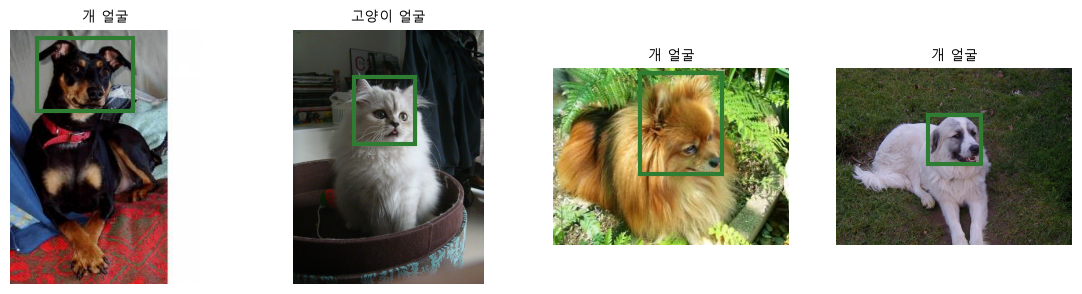

In [4]:
from torch.utils.data import default_collate  # 기본 DataLoader의 묶기 함수

# 기본 묶기: 사진 크기가 다르면 한 텐서로 쌓을 수 없음
try:
    next(iter(DataLoader(train_ds, batch_size=4)))
except RuntimeError as e:
    print("기본 묶기 · 사진 →", str(e).split(",")[0])


# 사진 크기가 같아도 박스 개수가 다르면 target도 못 쌓음
try:
    default_collate([make_target("Abyssinian_173"), make_target("Bengal_105")])
except RuntimeError as e:
    print("기본 묶기 · 박스 1개 + 2개 →", str(e).split(",")[0])


# collate_fn: 쌓지 말고 목록 두 개로 (이미지끼리 · target끼리)
def collate_fn(batch):
    return tuple(zip(*batch))  # [(img, t), (img, t)] → ((img, img), (t, t))


images, targets = collate_fn([train_ds[0], train_ds[1]])
print("collate_fn →", type(images).__name__, len(images), "장 ·",
      [tuple(im.shape) for im in images])


# 학습용 DataLoader: 16장씩 · 섞는 순서 seed 고정
train_loader = DataLoader(train_ds, batch_size=16, shuffle=True,
                          collate_fn=collate_fn,
                          generator=torch.Generator().manual_seed(0))
print("train batch 수:", len(train_loader), "(600 ÷ 16 → 올림)")


# 첫 batch 점검: 학습 걸기 전에 숫자 약속 확인
def check_batch(images, targets):
    for im, t in zip(images, targets):
        b, lab = t["boxes"], t["labels"]
        assert im.dtype == torch.float32 and im.shape[0] == 3
        assert b.dtype == torch.float32 and b.ndim == 2 and b.shape[1] == 4
        assert lab.dtype == torch.int64 and len(lab) == len(b)
        assert (b[:, 0] < b[:, 2]).all() and (b[:, 1] < b[:, 3]).all()
        assert set(lab.tolist()) <= {1, 2}  # 0(배경)은 정답에 없음
    return f"{len(images)}장 점검 통과"


images, targets = next(iter(train_loader))
print(check_batch(images, targets))
fig, axes = plt.subplots(1, 4, figsize=(14, 3.3))
for ax, im, t in zip(axes, images, targets):
    show(im, gt=t["boxes"], ax=ax,
         title=" · ".join(CLASSES[c] for c in t["labels"].tolist()))
plt.show()

**예측 정답** · `RuntimeError` — `stack`은 같은 모양끼리만 쌓을 수 있음

**결과 해설**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">출력</th>
<th style="text-align: left;">의미</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>기본 묶기 · 사진 → stack expects each tensor to be equal size</code></td>
<td style="text-align: left;">사진 크기가 달라 한 텐서로 못 쌓음</td>
</tr>
<tr>
<td style="text-align: left;"><code>기본 묶기 · 박스 1개 + 2개 → stack expects each tensor to be equal size</code></td>
<td style="text-align: left;">사진 크기를 맞춰도 박스 수가 다르면 target도 못 쌓음 (박스 2개인 고양이 사진)</td>
</tr>
<tr>
<td style="text-align: left;"><code>collate_fn → tuple 2 장 · [(3, 500, 333), (3, 375, 500)]</code></td>
<td style="text-align: left;">쌓지 않고 목록 → 크기가 달라도 그대로</td>
</tr>
<tr>
<td style="text-align: left;"><code>train batch 수: 38 (600 ÷ 16 → 올림)</code></td>
<td style="text-align: left;">37 × 16 = 592장 + 마지막 8장</td>
</tr>
<tr>
<td style="text-align: left;"><code>16장 점검 통과</code></td>
<td style="text-align: left;">모양 · 자료형 · x1 &lt; x2 · 라벨 1 · 2 확인 → 그림으로 박스 위치까지</td>
</tr>
</tbody>
</table>

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">기본 묶기 (<code>default_collate</code>)</td>
<td style="text-align: left;">샘플들을 한 텐서로 쌓음 (<code>stack</code>)</td>
<td style="text-align: left;">모양이 같은 분류 · 회귀 데이터</td>
</tr>
<tr>
<td style="text-align: left;"><code>collate_fn = tuple(zip(*batch))</code></td>
<td style="text-align: left;">쌓지 않고 이미지 목록 · target 목록</td>
<td style="text-align: left;">사진 크기 · 박스 수가 다른 탐지 (필수)</td>
</tr>
<tr>
<td style="text-align: left;">크기를 미리 맞춰 쌓기</td>
<td style="text-align: left;">사진은 쌓여도 박스 수가 다르면 실패</td>
<td style="text-align: left;">쓰지 않음 (조용히 [16, 1, 4]로 묶이는 함정)</td>
</tr>
<tr>
<td style="text-align: left;">첫 batch 점검</td>
<td style="text-align: left;">모양 · 자료형 · 박스 순서 · 라벨 범위</td>
<td style="text-align: left;">긴 학습 전에 한 번</td>
</tr>
</tbody>
</table>

> ⚠️ **주의** · 박스가 모두 1개인 사진끼리만 묶이면 기본 묶기가 조용히 `[16, 1, 4]`로 성공 → 다른 batch에서 갑자기 에러, 탐지는 처음부터 `collate_fn`

> ✅ **한 줄 정리** · 탐지 DataLoader는 `collate_fn=lambda b: tuple(zip(*b))`로 사진과 target을 목록으로 묶고, 첫 batch를 점검한 뒤 학습한다.

**딥러닝 코드에서는** · torchvision 탐지 모델은 `model(images, targets)`에서 images = 텐서 목록, targets = dict 목록을 받음 → `collate_fn` 결과 모양 그대로

#### 1장 정리 · 소속별 최종 요약표

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">함수·문법</th>
<th style="text-align: left;">소속</th>
<th style="text-align: left;">역할</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>train_test_split(..., stratify=, random_state=)</code></td>
<td style="text-align: left;">sklearn.model_selection</td>
<td style="text-align: left;">비율을 지켜 나누기 · 같은 분할 재현</td>
</tr>
<tr>
<td style="text-align: left;"><code>Dataset</code> · <code>__len__</code> · <code>__getitem__</code></td>
<td style="text-align: left;">torch.utils.data</td>
<td style="text-align: left;">번호 → (이미지, target)</td>
</tr>
<tr>
<td style="text-align: left;"><code>collate_fn = tuple(zip(*batch))</code></td>
<td style="text-align: left;">DataLoader 인자</td>
<td style="text-align: left;">사진 · target을 목록으로 묶기</td>
</tr>
<tr>
<td style="text-align: left;"><code>DataLoader(shuffle=True, generator=)</code></td>
<td style="text-align: left;">torch.utils.data</td>
<td style="text-align: left;">섞는 순서 고정</td>
</tr>
<tr>
<td style="text-align: left;"><code>default_collate</code></td>
<td style="text-align: left;">torch.utils.data</td>
<td style="text-align: left;">기본 묶기 (쌓기)</td>
</tr>
</tbody>
</table>

---
## 2. 박스 증강

> **연결** · 1장에서 Dataset이 (이미지, target)을 돌려주게 했다 → 데이터를 늘리는 증강도 `__getitem__` 안에서 사진과 박스를 함께 바꿔야 정답이 유지됨

**흐름 위치** · ③ 전처리 — train에만 확률 0.5 좌우 뒤집기

### 2-1. `A` 박스를 따라가는 좌우 뒤집기 · `flip_boxes()` · `hflip()` <sub>Day02 D2-3</sub>

> 🎯 **Dataset 안에서 좌우 뒤집기 증강을 할 때 박스는 어떻게 처리하는가?**

💡 **쉽게 말하면** 사진을 거울에 비추면 **얼굴 스티커도 거울 위치로 옮겨 붙여야** 함. 사진만 뒤집으면 스티커가 엉뚱한 곳에 남아 있는데도 숫자 점검은 통과해 버림.

**실행 흐름** · flip_boxes · hflip 정의 → train 박스 600개를 사진만 뒤집었을 때 IoU → 두 번 뒤집기 = 원래 → 한 epoch에 뒤집히는 수 → 그림 3장

**먼저 예측** · 사진만 뒤집었을 때 원래 박스가 실제 얼굴과 IoU 0.5 이상(겉보기엔 맞음)인 박스는 몇 개일까? — 답은 코드 실행 결과 아래에

train 박스 600 개 · 사진만 뒤집었을 때
  IoU 0 (완전히 빗나감): 104개 | IoU 0.5 이상 (겉보기엔 맞음): 286개
두 번 뒤집은 뒤 최대 오차: 0.0
한 epoch에 뒤집히는 사진: 299 / 600


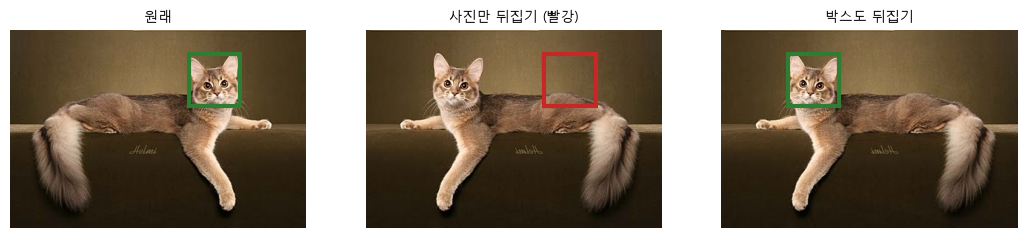

Abyssinian_173 [241.0, 31.0, 310.0, 102.0] → [90.0, 31.0, 159.0, 102.0]


In [5]:
# 좌우 뒤집기: 박스도 x1' = W - x2, x2' = W - x1 (객체탐지-1 2-3)
def flip_boxes(boxes, W):
    out = boxes.clone()
    out[:, 0] = W - boxes[:, 2]
    out[:, 2] = W - boxes[:, 0]
    return out


def hflip(image, target):
    W = image.shape[-1]  # 사진 폭
    return image.flip(-1), {**target, "boxes": flip_boxes(target["boxes"], W)}


def xml_width(stem):
    return int(ET.parse(XMLS / f"{stem}.xml").getroot().findtext("size/width"))


# 사진만 뒤집으면? train 박스마다 원래 박스 vs 실제 얼굴 자리의 IoU
ious, worst = [], 0.0
for s in train_ids:
    b, W = make_target(s)["boxes"], xml_width(s)
    ious += box_iou(b, flip_boxes(b, W)).diagonal().tolist()
    twice = flip_boxes(flip_boxes(b, W), W)  # 두 번 뒤집기
    worst = max(worst, (twice - b).abs().max().item())
ious = torch.tensor(ious)
print("train 박스", len(ious), "개 · 사진만 뒤집었을 때")
print(f"  IoU 0 (완전히 빗나감): {(ious == 0).sum().item()}개 |"
      f" IoU 0.5 이상 (겉보기엔 맞음): {(ious >= 0.5).sum().item()}개")
print("두 번 뒤집은 뒤 최대 오차:", worst)


# train에만 · 꺼낼 때마다 확률 0.5 → 한 epoch에 뒤집히는 사진 수
gen = torch.Generator().manual_seed(1)  # PetFaces와 같은 seed
n_flip = sum(bool(torch.rand(1, generator=gen) < 0.5) for _ in train_ids)
print(f"한 epoch에 뒤집히는 사진: {n_flip} / {len(train_ids)}")


# 그림: 원래 · 사진만 뒤집기(빨강) · 박스도 뒤집기
stem = "Abyssinian_173"
image, target = TF.to_tensor(load_image(stem)), make_target(stem)
image_f, target_f = hflip(image, target)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.3))
show(image, gt=target["boxes"], title="원래", ax=axes[0])
show(image_f, bad=target["boxes"], title="사진만 뒤집기 (빨강)", ax=axes[1])
show(image_f, gt=target_f["boxes"], title="박스도 뒤집기", ax=axes[2])
plt.show()
print(stem, target["boxes"][0].tolist(), "→", target_f["boxes"][0].tolist())

**예측 정답** · `286`개 (약 절반) — 얼굴이 가운데 가까우면 틀린 박스도 맞아 보여서 그림 몇 장으로는 못 잡음

**결과 해설**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">출력</th>
<th style="text-align: left;">의미</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>IoU 0 (완전히 빗나감): 104개 &#124; IoU 0.5 이상 (겉보기엔 맞음): 286개</code></td>
<td style="text-align: left;">사진만 뒤집으면 600개 중 104개는 완전히 빗나가고 286개는 맞아 보이는 함정</td>
</tr>
<tr>
<td style="text-align: left;"><code>두 번 뒤집은 뒤 최대 오차: 0.0</code></td>
<td style="text-align: left;">flip_boxes가 정확히 되돌아옴 → 식 점검</td>
</tr>
<tr>
<td style="text-align: left;"><code>한 epoch에 뒤집히는 사진: 299 / 600</code></td>
<td style="text-align: left;">확률 0.5 · seed 1 → 약 절반, epoch마다 다른 사진</td>
</tr>
<tr>
<td style="text-align: left;"><code>Abyssinian_173 [241.0, 31.0, 310.0, 102.0] → [90.0, 31.0, 159.0, 102.0]</code></td>
<td style="text-align: left;">400 - 310 = 90, 400 - 241 = 159 (객체탐지-1 2-3과 같은 계산)</td>
</tr>
</tbody>
</table>

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">사진만 뒤집기</td>
<td style="text-align: left;">박스는 제자리 → 에러 없이 틀린 정답</td>
<td style="text-align: left;">쓰지 않음 (분류에서만 안전)</td>
</tr>
<tr>
<td style="text-align: left;">박스도 뒤집기</td>
<td style="text-align: left;">x1' = W - x2, x2' = W - x1, y · 라벨 그대로</td>
<td style="text-align: left;">탐지 좌우 뒤집기 (기본)</td>
</tr>
<tr>
<td style="text-align: left;">train에만 · 확률 0.5</td>
<td style="text-align: left;">epoch마다 다른 사진이 뒤집힘</td>
<td style="text-align: left;">학습 데이터를 늘리는 효과</td>
</tr>
<tr>
<td style="text-align: left;">val · test에도 뒤집기</td>
<td style="text-align: left;">평가 기준이 매번 바뀜</td>
<td style="text-align: left;">쓰지 않음 (평가는 고정)</td>
</tr>
<tr>
<td style="text-align: left;">상하 뒤집기 · 큰 회전</td>
<td style="text-align: left;">거꾸로 선 얼굴 · 박스가 커짐</td>
<td style="text-align: left;">실제 사진에 없으면 쓰지 않음</td>
</tr>
</tbody>
</table>

> ⚠️ **주의** · val · test에는 뒤집기를 켜지 않음 → 평가 사진이 매번 바뀌면 epoch끼리 비교가 안 됨

> ✅ **한 줄 정리** · 좌우 뒤집기는 사진과 박스를 함께 바꾸고(`x1' = W - x2`), train에만 확률 0.5로 적용한다.

**딥러닝 코드에서는** · 실전에서는 `transforms.v2.RandomHorizontalFlip(0.5)`에 `tv_tensors.BoundingBoxes`를 넘기면 박스까지 자동 (객체탐지-1 2-3에서 검증)

#### 2장 정리 · 소속별 최종 요약표

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">함수·문법</th>
<th style="text-align: left;">소속</th>
<th style="text-align: left;">역할</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>flip_boxes(boxes, W)</code></td>
<td style="text-align: left;">직접 만든 함수</td>
<td style="text-align: left;">x1' = W - x2 · x2' = W - x1</td>
</tr>
<tr>
<td style="text-align: left;"><code>image.flip(-1)</code></td>
<td style="text-align: left;">torch</td>
<td style="text-align: left;">텐서 좌우 뒤집기 (마지막 축 = 가로)</td>
</tr>
<tr>
<td style="text-align: left;"><code>torch.Generator().manual_seed(1)</code></td>
<td style="text-align: left;">torch</td>
<td style="text-align: left;">증강 전용 난수</td>
</tr>
<tr>
<td style="text-align: left;"><code>v2.RandomHorizontalFlip</code> + <code>BoundingBoxes</code></td>
<td style="text-align: left;">torchvision.transforms.v2</td>
<td style="text-align: left;">같은 일을 라이브러리로 (객체탐지-1 2-3)</td>
</tr>
</tbody>
</table>

---
## 3. 헤드 교체

> **연결** · 2장까지 데이터 준비가 끝났다 → COCO 91칸으로 학습된 탐지 모델의 마지막 판정 층을 우리 3칸(배경 · 고양이 얼굴 · 개 얼굴)으로 바꿈. 1단계(SSD)와 2단계(Faster R-CNN)는 바꾸는 층이 다름

**흐름 위치** · ④ 모델 — 몸통 · 위치 헤드는 COCO에서, 분류 헤드는 새로

### 3-1. `A` SSD 분류 헤드 교체 · `SSDClassificationHead()` <sub>Day02 D2-4</sub>

> 🎯 **COCO 91칸으로 학습된 SSD를 3칸(배경 · 고양이 얼굴 · 개 얼굴)으로 바꾸려면 무엇을 바꿔야 하는가?**

💡 **쉽게 말하면** 분류 헤드는 **91칸짜리 답안지**. 표지에 "3칸"이라고 적는다고 답안지 칸이 줄지 않음 → 3칸짜리 새 답안지(새 층)를 끼워야 함.

**실행 흐름** · 숫자만 바꾸기 → 점수 모양 · 손실 계산 확인 → `SSDClassificationHead`로 새 헤드 → 점수 모양 → 몸통이 COCO와 같은지 · 파라미터 수

**먼저 예측** · `num_classes = 3`만 바꾸면 클래스 점수 모양은? — 답은 코드 실행 결과 아래에

In [6]:
from torchvision.models.detection import SSD300_VGG16_Weights, ssd300_vgg16
from torchvision.models.detection.ssd import SSDClassificationHead

SSD_W = SSD300_VGG16_Weights.COCO_V1  # COCO 91칸으로 학습된 SSD


# 사진 한 장 → 분류 헤드의 클래스 점수 모양
def head_shape(model, x):
    model.eval()
    with torch.no_grad():
        images, _ = model.transform([x])  # 300×300으로 맞춤
        feats = list(model.backbone(images.tensors).values())
        return tuple(model.head(feats)["cls_logits"].shape)


x0 = TF.to_tensor(load_image("Abyssinian_173"))


# 방법 1: 숫자만 바꾸기 → 층은 그대로 91칸
tagged = ssd300_vgg16(weights=SSD_W)
tagged.head.classification_head.num_classes = 3
print("숫자만 바꾸기 → 점수 모양", head_shape(tagged, x0), "| 첫 층 출력",
      tagged.head.classification_head.module_list[0].out_channels)
tagged.train()
loss = tagged([x0], [make_target("Abyssinian_173")])  # 그래도 에러 없음
print("  학습 손실 계산:", list(loss), "→ 에러 없이 1번 칸 = COCO person으로 학습")


# 방법 2: 분류 헤드를 3칸으로 새로 만들어 끼우기
def make_ssd(num_classes=3):
    m = ssd300_vgg16(weights=SSD_W)
    old = m.head.classification_head
    in_ch = [conv.in_channels for conv in old.module_list]  # 맵마다 채널
    anchors = m.anchor_generator.num_anchors_per_location()  # 칸마다 박스 수
    m.head.classification_head = SSDClassificationHead(in_ch, anchors,
                                                       num_classes)
    return m


torch.manual_seed(0)  # 새 층의 무작위 시작값 고정
ssd = make_ssd()
print("헤드 새로 끼우기 → 점수 모양", head_shape(ssd, x0), "| 첫 층 출력",
      ssd.head.classification_head.module_list[0].out_channels, "= 4 × 3")


# 무엇이 COCO 그대로이고 무엇이 새것인가
def n_params(module):
    return sum(p.numel() for p in module.parameters())


same = all(torch.equal(a, b) for a, b in zip(
    ssd.backbone.state_dict().values(), tagged.backbone.state_dict().values()))
print(f"몸통 COCO와 같음: {same} | 분류 헤드 파라미터: COCO "
      f"{n_params(tagged.head.classification_head):,} → 새 헤드 "
      f"{n_params(ssd.head.classification_head):,}")

숫자만 바꾸기 → 점수 모양 (1, 8732, 91) | 첫 층 출력 364


  학습 손실 계산: ['bbox_regression', 'classification'] → 에러 없이 1번 칸 = COCO person으로 학습


헤드 새로 끼우기 → 점수 모양 (1, 8732, 3) | 첫 층 출력 12 = 4 × 3


몸통 COCO와 같음: True | 분류 헤드 파라미터: COCO 12,163,242 → 새 헤드 400,986


**예측 정답** · `(1, 8732, 91)` 그대로 — 층은 만들 때 정한 91칸, 손실 계산도 에러 없이 돌아감

**결과 해설**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">출력</th>
<th style="text-align: left;">의미</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>숫자만 바꾸기 → 점수 모양 (1, 8732, 91) &#124; 첫 층 출력 364</code></td>
<td style="text-align: left;">이름표만 붙고 층은 4 × 91 = 364 그대로</td>
</tr>
<tr>
<td style="text-align: left;"><code>학습 손실 계산: ['bbox_regression', 'classification']</code></td>
<td style="text-align: left;">에러 없음 → 우리 1번(고양이 얼굴)을 COCO 1번(person) 칸으로 학습하는 조용한 버그</td>
</tr>
<tr>
<td style="text-align: left;"><code>헤드 새로 끼우기 → 점수 모양 (1, 8732, 3) &#124; 첫 층 출력 12 = 4 × 3</code></td>
<td style="text-align: left;">디폴트 박스 8732개마다 3칸</td>
</tr>
<tr>
<td style="text-align: left;"><code>몸통 COCO와 같음: True &#124; 분류 헤드 파라미터: COCO 12,163,242 → 새 헤드 400,986</code></td>
<td style="text-align: left;">몸통 · 위치 헤드는 COCO에서 출발, 분류 헤드만 무작위 시작</td>
</tr>
</tbody>
</table>

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">숫자만 바꾸기 (<code>num_classes = 3</code>)</td>
<td style="text-align: left;">이름표만 바뀌고 층은 91칸 그대로, 에러도 없음</td>
<td style="text-align: left;">쓰지 않음 (조용한 버그)</td>
</tr>
<tr>
<td style="text-align: left;">분류 헤드 새로 끼우기</td>
<td style="text-align: left;">출력 채널 = 앵커 수 × 3, 무작위 시작</td>
<td style="text-align: left;">내 클래스 수로 바꿀 때 (기본)</td>
</tr>
<tr>
<td style="text-align: left;">몸통 · 위치 헤드</td>
<td style="text-align: left;">COCO 값 그대로에서 시작</td>
<td style="text-align: left;">사전학습의 이점을 살림</td>
</tr>
<tr>
<td style="text-align: left;"><code>weights=None</code></td>
<td style="text-align: left;">전부 무작위 시작</td>
<td style="text-align: left;">데이터가 아주 많을 때만</td>
</tr>
</tbody>
</table>

> ⚠️ **주의** · 에러가 안 난다고 맞는 것이 아님 → 헤드를 바꾼 뒤 클래스 점수의 마지막 칸 수를 반드시 확인 (4-1)

> ✅ **한 줄 정리** · 클래스 수는 층을 만들 때 출력 채널에 들어가므로, 숫자만 바꾸지 말고 분류 헤드를 새 클래스 수로 새로 만들어 끼운다.

**딥러닝 코드에서는** · `model.head.classification_head = SSDClassificationHead(in_channels, num_anchors, num_classes)` — `num_classes`는 배경 포함

### 3-2. `A` Faster R-CNN 헤드 교체 · `FastRCNNPredictor()` <sub>Faster R-CNN 노트북 · Day01 D1-7</sub>

> 🎯 **2단계 탐지기 Faster R-CNN은 어느 층을 바꿔 내 클래스에 맞추는가?**

💡 **쉽게 말하면** Faster R-CNN은 **후보를 고르는 사람(RPN)** 과 **후보마다 판정하는 사람(box_predictor)** 이 따로 있음. 후보 고르기는 클래스와 상관없으니 그대로 두고, 판정하는 사람만 3칸짜리로 바꿈.

**실행 흐름** · COCO Faster R-CNN 불러오기 → 교체 전 `cls_score` · `bbox_pred` → `FastRCNNPredictor(1024, 3)` → 교체 후 → 예측 라벨 종류 · 파라미터

**먼저 예측** · 교체 후 `bbox_pred`의 출력 수는? — 답은 코드 실행 결과 아래에

In [7]:
from torchvision.models.detection import (FasterRCNN_ResNet50_FPN_Weights,
                                          fasterrcnn_resnet50_fpn)
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor

# COCO로 학습된 Faster R-CNN의 마지막 판정 층
frcnn = fasterrcnn_resnet50_fpn(
    weights=FasterRCNN_ResNet50_FPN_Weights.COCO_V1)
old = frcnn.roi_heads.box_predictor
print("교체 전:", old.cls_score, "|", old.bbox_pred)


# 마지막 층(FastRCNNPredictor)만 3칸으로 바꿔 끼우기
in_features = old.cls_score.in_features  # 후보 하나의 특징 길이 1024
torch.manual_seed(0)
frcnn.roi_heads.box_predictor = FastRCNNPredictor(in_features, 3)
new = frcnn.roi_heads.box_predictor
print("교체 후:", new.cls_score, "|", new.bbox_pred)


# 새 헤드로 예측하면 라벨은 1 · 2만 나옴 (학습 전이라 박스는 엉터리)
frcnn = frcnn.to(device).eval()
with torch.no_grad():
    out = frcnn([x0.to(device)])[0]
print("예측 라벨 종류:", sorted(set(out["labels"].tolist())),
      "| 예측 박스 수:", len(out["boxes"]))
print("파라미터: 전체", f"{n_params(frcnn):,}", "· 새 헤드",
      f"{n_params(new):,}")

교체 전: Linear(in_features=1024, out_features=91, bias=True) | Linear(in_features=1024, out_features=364, bias=True)
교체 후: Linear(in_features=1024, out_features=3, bias=True) | Linear(in_features=1024, out_features=12, bias=True)


예측 라벨 종류: [1, 2] | 예측 박스 수: 100
파라미터: 전체 41,304,286 · 새 헤드 15,375


**예측 정답** · `12` = 3클래스 × 4 — Faster R-CNN은 박스 보정도 클래스마다 따로 냄

**결과 해설**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">출력</th>
<th style="text-align: left;">의미</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>교체 전: Linear(in_features=1024, out_features=91, bias=True) &#124; Linear(in_features=1024, out_features=364, bias=True)</code></td>
<td style="text-align: left;">분류 91칸 · 박스 보정 91 × 4 = 364</td>
</tr>
<tr>
<td style="text-align: left;"><code>교체 후: Linear(in_features=1024, out_features=3, bias=True) &#124; Linear(in_features=1024, out_features=12, bias=True)</code></td>
<td style="text-align: left;">분류 3칸 · 박스 보정 3 × 4 = 12</td>
</tr>
<tr>
<td style="text-align: left;"><code>예측 라벨 종류: [1, 2] &#124; 예측 박스 수: 100</code></td>
<td style="text-align: left;">구조는 미션에 맞음 (학습 전이라 박스는 엉터리)</td>
</tr>
<tr>
<td style="text-align: left;"><code>파라미터: 전체 41,304,286 · 새 헤드 15,375</code></td>
<td style="text-align: left;">새로 배울 층은 아주 작고 나머지는 COCO에서 출발</td>
</tr>
</tbody>
</table>

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">SSD 헤드 교체</td>
<td style="text-align: left;"><code>SSDClassificationHead(in_channels, anchors, 3)</code> · 특징 맵 6개마다 Conv</td>
<td style="text-align: left;">1단계 탐지기 · 빠른 추론</td>
</tr>
<tr>
<td style="text-align: left;">Faster R-CNN 헤드 교체</td>
<td style="text-align: left;"><code>FastRCNNPredictor(1024, 3)</code> · Linear 두 개만</td>
<td style="text-align: left;">2단계 탐지기 · 정확도 우선</td>
</tr>
<tr>
<td style="text-align: left;">바꾸는 곳</td>
<td style="text-align: left;">SSD = 분류 헤드만 (위치 헤드는 클래스 무관), Faster R-CNN = 분류 + 클래스별 박스 보정</td>
<td style="text-align: left;">Faster R-CNN은 박스 보정도 클래스마다라 같이 바뀜</td>
</tr>
<tr>
<td style="text-align: left;">손실 이름</td>
<td style="text-align: left;">SSD 2개 vs Faster R-CNN 4개 (RPN 2 + 판정 2)</td>
<td style="text-align: left;">학습 로그를 읽을 때</td>
</tr>
</tbody>
</table>

> ⚠️ **주의** · SSD처럼 분류 층만 바꾸면 안 됨 → Faster R-CNN은 `box_predictor` 전체(분류 + 박스 보정)를 `FastRCNNPredictor`로 교체

> ✅ **한 줄 정리** · Faster R-CNN은 `roi_heads.box_predictor`를 `FastRCNNPredictor(in_features, num_classes)`로 바꿔 분류와 클래스별 박스 보정을 함께 새로 만든다.

**딥러닝 코드에서는** · torchvision 공식 튜토리얼 그대로: `in_features = model.roi_heads.box_predictor.cls_score.in_features` → `FastRCNNPredictor(in_features, num_classes)`

#### 3장 정리 · 소속별 최종 요약표

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">함수·문법</th>
<th style="text-align: left;">소속</th>
<th style="text-align: left;">역할</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>SSDClassificationHead(in_channels, num_anchors, num_classes)</code></td>
<td style="text-align: left;">torchvision.models.detection.ssd</td>
<td style="text-align: left;">SSD 분류 헤드</td>
</tr>
<tr>
<td style="text-align: left;"><code>anchor_generator.num_anchors_per_location()</code></td>
<td style="text-align: left;">SSD 속성</td>
<td style="text-align: left;">특징 맵 칸마다 디폴트 박스 수</td>
</tr>
<tr>
<td style="text-align: left;"><code>FastRCNNPredictor(in_features, num_classes)</code></td>
<td style="text-align: left;">torchvision.models.detection.faster_rcnn</td>
<td style="text-align: left;">Faster R-CNN 판정 층 (분류 + 박스 보정)</td>
</tr>
<tr>
<td style="text-align: left;"><code>roi_heads.box_predictor</code></td>
<td style="text-align: left;">Faster R-CNN 속성</td>
<td style="text-align: left;">바꿀 자리</td>
</tr>
</tbody>
</table>

---
## 4. 스모크 테스트

> **연결** · 3장에서 헤드를 바꿨다 → 수 분 ~ 수 시간짜리 학습을 걸기 전에 모양 · 손실 · 모드를 1분 안에 확인해 연결 실수를 잡음

**흐름 위치** · ⑤ 학습 직전 — 모양 한 줄 · 몇 step · 모드별 출력

### 4-1. `A` 스모크 테스트 · `assert` · `train_step()` <sub>Day02 D2-5</sub>

> 🎯 **긴 학습을 걸기 전에 1분 안에 무엇을 확인하는가?**

💡 **쉽게 말하면** 새 기계를 오래 돌리기 전에 **전원을 켜고 잠깐 돌려 연기가 나는지** 보는 것. 모양 한 줄 · 몇 step 학습으로 연결 실수를 먼저 잡음.

**실행 흐름** · 확인 1: 점수 마지막 칸 = 3 (숫자만 바꾼 모델 · 교체한 모델) → 확인 2: SSD 10 step 손실 → Faster R-CNN 2 step 손실 이름

**먼저 예측** · 숫자만 바꾼 모델(3-1)은 스모크 테스트의 어디서 멈출까? — 답은 코드 실행 결과 아래에

In [8]:
# 확인 1: 클래스 점수 마지막 칸 수 = 3 (숫자만 바꾼 모델을 여기서 잡음)
def check_head(model, x, num_classes=3):
    shape = head_shape(model, x)
    assert shape[-1] == num_classes, f"점수 {shape[-1]}칸 — {num_classes}칸이어야 함"
    return shape


try:
    check_head(tagged, x0)
except AssertionError as e:
    print("숫자만 바꾼 모델 → 멈춤:", e)
print("헤드 교체 모델 → 통과:", check_head(ssd, x0))
del tagged  # 잘못 만든 모델은 버림


# 확인 2: 몇 step만 학습 → 손실이 숫자인가 · 내려가는가
def train_step(model, images, targets, optimizer):
    images = [x.to(device) for x in images]
    targets = [{k: v.to(device) for k, v in t.items()} for t in targets]
    loss_dict = model(images, targets)  # 학습 모드 → 손실 dict
    loss = sum(loss_dict.values())  # 손실 여러 개를 더해 하나로
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    return {k: v.item() for k, v in loss_dict.items()}


ssd = ssd.to(device).train()
opt = torch.optim.SGD(ssd.parameters(), lr=0.001, momentum=0.9,
                      weight_decay=5e-4)
for step, (images, targets) in enumerate(train_loader, 1):
    losses = train_step(ssd, images, targets, opt)
    assert all(map(math.isfinite, losses.values())), f"step {step}: {losses}"
    if step in (1, 5, 10):
        print(f"SSD step {step:2d} | 위치 {losses['bbox_regression']:.2f}"
              f" · 분류 {losses['classification']:.2f}")
    if step == 10:
        break


# Faster R-CNN도 같은 train_step으로 2 step (사진 4장) → 손실 이름이 다름
frcnn.train()
params = [p for p in frcnn.parameters() if p.requires_grad]
opt_f = torch.optim.SGD(params, lr=0.005, momentum=0.9, weight_decay=5e-4)
for step in (1, 2):
    losses = train_step(frcnn, images[:4], targets[:4], opt_f)
    print(f"Faster R-CNN step {step} | 손실 {len(losses)}개:", list(losses))
del frcnn, opt_f  # GPU 메모리 비우기

숫자만 바꾼 모델 → 멈춤: 점수 91칸 — 3칸이어야 함


헤드 교체 모델 → 통과: (1, 8732, 3)


SSD step  1 | 위치 2.35 · 분류 15.88


SSD step  5 | 위치 1.91 · 분류 5.89


SSD step 10 | 위치 1.96 · 분류 5.35


Faster R-CNN step 1 | 손실 4개: ['loss_classifier', 'loss_box_reg', 'loss_objectness', 'loss_rpn_box_reg']


Faster R-CNN step 2 | 손실 4개: ['loss_classifier', 'loss_box_reg', 'loss_objectness', 'loss_rpn_box_reg']


**예측 정답** · 확인 1 (모양 한 줄) — `점수 91칸 — 3칸이어야 함`

**결과 해설**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">출력</th>
<th style="text-align: left;">의미</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>숫자만 바꾼 모델 → 멈춤: 점수 91칸 — 3칸이어야 함</code></td>
<td style="text-align: left;">3-1의 조용한 버그를 학습 전에 한 줄로 잡음</td>
</tr>
<tr>
<td style="text-align: left;"><code>헤드 교체 모델 → 통과: (1, 8732, 3)</code></td>
<td style="text-align: left;">모양 통과</td>
</tr>
<tr>
<td style="text-align: left;"><code>SSD step  1 &#124; 위치 2.35 · 분류 15.88</code></td>
<td style="text-align: left;">무작위 분류 헤드라 분류 손실이 큼</td>
</tr>
<tr>
<td style="text-align: left;"><code>SSD step 10 &#124; 위치 1.96 · 분류 5.35</code></td>
<td style="text-align: left;">10 step 만에 분류 손실이 크게 줄어듦 → 연결 정상</td>
</tr>
<tr>
<td style="text-align: left;"><code>Faster R-CNN step 1 &#124; 손실 4개: [&#x27;loss_classifier&#x27;, &#x27;loss_box_reg&#x27;, &#x27;loss_objectness&#x27;, &#x27;loss_rpn_box_reg&#x27;]</code></td>
<td style="text-align: left;">2단계라 RPN 손실 2개 + 판정 손실 2개 (SSD는 2개)</td>
</tr>
</tbody>
</table>

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">확인 1 · 모양 한 줄</td>
<td style="text-align: left;">클래스 점수 마지막 칸 = 3</td>
<td style="text-align: left;">헤드 교체 실수 (91칸 그대로)</td>
</tr>
<tr>
<td style="text-align: left;">확인 2 · 몇 step</td>
<td style="text-align: left;">손실이 숫자인가 · 내려가는가</td>
<td style="text-align: left;">연결 오류 · nan · 잘못된 박스</td>
</tr>
<tr>
<td style="text-align: left;">스모크 테스트</td>
<td style="text-align: left;">1분 확인 · 망가지지 않았다는 뜻</td>
<td style="text-align: left;">긴 학습 전 매번</td>
</tr>
<tr>
<td style="text-align: left;">본 학습</td>
<td style="text-align: left;">수 분 ~ 수 시간 · 잘 배웠는지는 val로</td>
<td style="text-align: left;">스모크 통과 뒤</td>
</tr>
</tbody>
</table>

> ⚠️ **주의** · 스모크 통과 = "당장 망가지지 않음"이지 "잘 배움"이 아님 → 성능은 val로 확인 (5장)

> ✅ **한 줄 정리** · 긴 학습 전에 모양 한 줄과 몇 step 학습으로 헤드 · 손실 · 데이터 연결을 확인한다.

**딥러닝 코드에서는** · `assert head_shape[-1] == num_classes` · `assert math.isfinite(loss)`를 학습 스크립트 맨 앞에 두면 매번 자동으로 점검

### 4-2. `A` train 모드와 eval 모드의 출력 · `model.train()` · `model.eval()` <sub>Day02 D2-5</sub>

> 🎯 **같은 탐지 모델이 train 모드와 eval 모드에서 돌려주는 것은 어떻게 다른가?**

💡 **쉽게 말하면** 같은 사람이라도 **연습 시간**(train)에는 채점표(손실)를, **시험 시간**(eval)에는 답안지(예측)를 냄. 모드를 착각하면 엉뚱한 것을 받아 루프가 멈춤.

**실행 흐름** · 같은 사진 2장 → train 모드 + 정답 · eval 모드 → 반환 종류 → 실수 2가지 재현 (eval인데 학습 · train인데 정답 없음)

**먼저 예측** · eval 모드에서 정답을 같이 넣으면 손실이 나올까? — 답은 코드 실행 결과 아래에

In [9]:
# 같은 모델 · 같은 사진 2장 → 모드마다 돌려주는 것이 다름
xs = [x.to(device) for x in images[:2]]
ts = [{k: v.to(device) for k, v in t.items()} for t in targets[:2]]
with torch.no_grad():
    ssd.train()
    out_train = ssd(xs, ts)
    ssd.eval()
    out_eval = ssd(xs)
print("train 모드 →", type(out_train).__name__, list(out_train))
print("eval 모드  →", type(out_eval).__name__, len(out_eval), "개 ·",
      list(out_eval[0]))


# 실수 1: 평가 뒤 train()을 깜빡하고 학습 루프를 돌리면
with torch.no_grad():
    out = ssd(xs, ts)  # eval 모드 · 정답을 줘도 예측이 나옴
try:
    sum(out.values())  # train_step 안의 그 줄
except AttributeError as e:
    print("eval 모드 + 정답 →", type(out).__name__, "→ 멈춤:", e)


# 실수 2: train 모드인데 정답 없이 예측하려 하면
ssd.train()
try:
    ssd(xs)
except AssertionError as e:
    print("train 모드 + 정답 없음 → 멈춤:", e)
del ssd, opt  # 스모크용 모델은 버리고 5장에서 새로 시작

train 모드 → dict ['bbox_regression', 'classification']
eval 모드  → list 2 개 · ['boxes', 'scores', 'labels']
eval 모드 + 정답 → list → 멈춤: 'list' object has no attribute 'values'
train 모드 + 정답 없음 → 멈춤: targets should not be none when in training mode


**예측 정답** · 안 나옴 — 정답을 무시하고 예측 list를 돌려줌 → 학습 루프의 `sum(out.values())`에서 멈춤

**결과 해설**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">출력</th>
<th style="text-align: left;">의미</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>train 모드 → dict ['bbox_regression', 'classification']</code></td>
<td style="text-align: left;">손실 dict → <code>sum(values())</code> → backward</td>
</tr>
<tr>
<td style="text-align: left;"><code>eval 모드  → list 2 개 · ['boxes', 'scores', 'labels']</code></td>
<td style="text-align: left;">사진마다 예측 dict</td>
</tr>
<tr>
<td style="text-align: left;"><code>eval 모드 + 정답 → list → 멈춤: 'list' object has no attribute 'values'</code></td>
<td style="text-align: left;">평가 뒤 <code>train()</code>을 깜빡한 실수</td>
</tr>
<tr>
<td style="text-align: left;"><code>train 모드 + 정답 없음 → 멈춤: targets should not be none when in training mode</code></td>
<td style="text-align: left;">예측 전에 <code>eval()</code>을 깜빡한 실수</td>
</tr>
</tbody>
</table>

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">train 모드 + 정답</td>
<td style="text-align: left;">손실 dict (<code>bbox_regression</code> · <code>classification</code>)</td>
<td style="text-align: left;">학습 루프</td>
</tr>
<tr>
<td style="text-align: left;">eval 모드 + 사진</td>
<td style="text-align: left;">사진마다 예측 dict의 list (boxes · scores · labels)</td>
<td style="text-align: left;">예측 · 채점</td>
</tr>
<tr>
<td style="text-align: left;">eval 모드 + 정답</td>
<td style="text-align: left;">정답을 무시하고 예측 list</td>
<td style="text-align: left;">실수: 학습 루프에서 <code>sum(out.values())</code> 에러</td>
</tr>
<tr>
<td style="text-align: left;">train 모드 + 정답 없음</td>
<td style="text-align: left;">AssertionError</td>
<td style="text-align: left;">실수: 예측 전에 <code>eval()</code>을 깜빡</td>
</tr>
</tbody>
</table>

> ⚠️ **주의** · epoch마다 val을 평가하면 모델이 eval 모드로 바뀐 채 다음 epoch로 넘어감 → 학습 함수 첫 줄에서 매번 `model.train()`

> ✅ **한 줄 정리** · 탐지 모델은 train 모드에서 정답을 받아 손실 dict를, eval 모드에서 사진만 받아 예측 list를 돌려준다.

**딥러닝 코드에서는** · 학습 함수 첫 줄 `model.train()`, 평가 함수 첫 줄 `model.eval()` + `torch.no_grad()` — 5-1의 `train_one_epoch` · `predict_all`

#### 4장 정리 · 소속별 최종 요약표

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">함수·문법</th>
<th style="text-align: left;">소속</th>
<th style="text-align: left;">역할</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>check_head(model, x)</code></td>
<td style="text-align: left;">직접 만든 함수</td>
<td style="text-align: left;">클래스 점수 마지막 칸 수 확인</td>
</tr>
<tr>
<td style="text-align: left;"><code>train_step(model, images, targets, opt)</code></td>
<td style="text-align: left;">직접 만든 함수</td>
<td style="text-align: left;">손실 dict → 합 → backward → step</td>
</tr>
<tr>
<td style="text-align: left;"><code>math.isfinite()</code></td>
<td style="text-align: left;">math</td>
<td style="text-align: left;">손실이 nan · inf가 아닌지</td>
</tr>
<tr>
<td style="text-align: left;"><code>model.train()</code> · <code>model.eval()</code></td>
<td style="text-align: left;">nn.Module 메서드</td>
<td style="text-align: left;">손실 dict ↔ 예측 list</td>
</tr>
</tbody>
</table>

---
## 5. 학습 · 체크포인트

> **연결** · 4장에서 연결을 확인했다 → 진짜 학습을 돌리며 lr 스케줄러를 epoch 끝마다 부르고, epoch마다 val mAP를 재서 last · best 체크포인트를 저장함

**흐름 위치** · ⑤ 학습 · ⑦ 저장 — RUN_A(뒤집기 없음) 5 epoch

### 5-1. `A` 학습 루프 · scheduler · epoch마다 평가 · `StepLR` · `scheduler.step()` <sub>Day02 D2-6 · Faster R-CNN 노트북</sub>

> 🎯 **학습 루프에서 lr 스케줄러는 언제 부르고, 어느 epoch가 좋은지는 무엇으로 판단하는가?**

💡 **쉽게 말하면** lr은 **걸음 크기**. 처음엔 성큼성큼, 목표 근처에선 조심조심. 스케줄러가 걸음을 줄여 주는데, 부르지 않으면 에러 없이 끝까지 성큼성큼 걷고, 너무 자주 부르면 곧바로 멈춰 섬.

**실행 흐름** · lr만 기록해 step() 위치 3가지 비교 → predict_all · evaluate(torchmetrics) · train_one_epoch · fit 정의 → RUN_A 학습 5 epoch (epoch마다 val mAP · last · best 저장)

**먼저 예측** · `scheduler.step()`을 batch마다 부르면 epoch 2의 lr은? — 답은 코드 실행 결과 아래에

In [10]:
EPOCHS, STEP_SIZE = 5, 4  # 5 epoch · epoch 4가 끝나면 lr 1/10


# scheduler.step()을 빼먹으면? (모델 없이 lr만 기록)
def lr_log(call):
    w = torch.nn.Parameter(torch.zeros(1))  # 가짜 파라미터 하나
    opt = torch.optim.SGD([w], lr=0.001, momentum=0.9)
    sch = torch.optim.lr_scheduler.StepLR(opt, step_size=STEP_SIZE, gamma=0.1)
    log = []
    for _ in range(EPOCHS):
        log.append(opt.param_groups[0]["lr"])  # 이번 epoch에 쓰는 lr
        for _ in range(len(train_loader)):
            opt.step()
            if call == "batch":
                sch.step()
        if call == "epoch":
            sch.step()
    return [f"{v:.0e}" for v in log]


for call, name in ((None, "step() 없음  "), ("epoch", "epoch 끝마다"),
                   ("batch", "batch마다   ")):
    print(name, "→ lr", lr_log(call))


# val 예측을 한 번 모으기 (모델이 낸 것 전부 · 신뢰도 0.01 이상)
def predict_all(model, ids, label_map=None):
    model.eval()
    out = []
    for k in range(0, len(ids), 16):
        stems = ids[k:k + 16]
        with torch.no_grad():
            preds = model([TF.to_tensor(load_image(s)).to(device)
                           for s in stems])
        for s, p in zip(stems, preds):
            p = {key: v.cpu() for key, v in p.items()}
            if label_map:  # COCO 번호 → 우리 번호, 나머지 클래스는 버림
                keep = torch.tensor([int(c) in label_map for c in p["labels"]],
                                    dtype=torch.bool)
                p = {key: v[keep] for key, v in p.items()}
                ours = [label_map[int(c)] for c in p["labels"]]
                p["labels"] = torch.tensor(ours, dtype=torch.int64)
            out.append({"id": s, **p})
    return out


# 지표: torchmetrics (계산 원리는 객체탐지-1 6장)
def evaluate(preds):
    res = {}
    for iou_thr, tag in ((None, ""), ([0.5], "50")):
        kw = {"iou_thresholds": iou_thr} if iou_thr else {}
        m = MeanAveragePrecision(class_metrics=True, **kw)
        m.warn_on_many_detections = False
        m.update([{k: r[k] for k in ("boxes", "scores", "labels")}
                  for r in preds], [make_target(r["id"]) for r in preds])
        r = m.compute()
        res["mAP" + tag] = r["map"].item()
        res["cat" + tag], res["dog" + tag] = r["map_per_class"].tolist()
        if not tag:
            res["mAP75"] = r["map_75"].item()
    return res


# 학습 한 바퀴: train() → batch마다 train_step → 사진 수로 가중 평균 손실
def train_one_epoch(model, loader, optimizer):
    model.train()  # 평가 뒤에도 epoch마다 학습 모드로
    total, seen = 0.0, 0
    for images, targets in loader:
        losses = train_step(model, images, targets, optimizer)
        assert all(map(math.isfinite, losses.values())), losses
        total += sum(losses.values()) * len(images)
        seen += len(images)
    return total / seen


# 학습 전체: epoch마다 scheduler.step · val 평가 · last 저장 · best 저장
def fit(name, flip):
    torch.manual_seed(0)  # 새 분류 헤드 시작값 고정 → 두 학습의 출발점 같음
    model = make_ssd().to(device)
    opt = torch.optim.SGD(model.parameters(), lr=0.001, momentum=0.9,
                          weight_decay=5e-4)
    sch = torch.optim.lr_scheduler.StepLR(opt, step_size=STEP_SIZE, gamma=0.1)
    loader = DataLoader(PetFaces(train_ids, flip=flip), batch_size=16,
                        shuffle=True, collate_fn=collate_fn,
                        generator=torch.Generator().manual_seed(0))
    history, best, t0 = [], -1.0, time.perf_counter()
    for epoch in range(1, EPOCHS + 1):
        lr = opt.param_groups[0]["lr"]
        loss = train_one_epoch(model, loader, opt)
        sch.step()  # epoch 끝마다 한 번
        val = evaluate(predict_all(model, val_ids))
        history.append({"epoch": epoch, "lr": lr, "loss": loss, **val})
        torch.save({"epoch": epoch, "model": model.state_dict(),  # last
                    "optimizer": opt.state_dict(),
                    "scheduler": sch.state_dict(), "history": history},
                   CKPT_DIR / f"{name}_last.pt")
        if val["mAP"] > best:  # best = val mAP@[.5:.95]가 가장 높을 때
            best = val["mAP"]
            torch.save({"epoch": epoch, "model": model.state_dict()},
                       CKPT_DIR / f"{name}_best.pt")
        print(f"[{name}] epoch {epoch} | lr {lr:.0e} | 손실 {loss:.3f} |"
              f" val mAP50 {val['mAP50']:.4f} · mAP {val['mAP']:.4f}")
    print(f"[{name}] 학습 시간 약 {(time.perf_counter() - t0) / 60:.0f}분"
          " (컴퓨터마다 다름)")
    return model, history


model_A, hist_A = fit("RUN_A", flip=False)  # 뒤집기 없음

step() 없음   → lr ['1e-03', '1e-03', '1e-03', '1e-03', '1e-03']
epoch 끝마다 → lr ['1e-03', '1e-03', '1e-03', '1e-03', '1e-04']
batch마다    → lr ['1e-03', '1e-12', '1e-22', '1e-31', '1e-41']


[RUN_A] epoch 1 | lr 1e-03 | 손실 6.335 | val mAP50 0.4676 · mAP 0.2401


[RUN_A] epoch 2 | lr 1e-03 | 손실 3.363 | val mAP50 0.8573 · mAP 0.4910


[RUN_A] epoch 3 | lr 1e-03 | 손실 2.263 | val mAP50 0.9385 · mAP 0.6078


[RUN_A] epoch 4 | lr 1e-03 | 손실 1.593 | val mAP50 0.9494 · mAP 0.6522


[RUN_A] epoch 5 | lr 1e-04 | 손실 1.186 | val mAP50 0.9448 · mAP 0.6738
[RUN_A] 학습 시간 약 24분 (컴퓨터마다 다름)


**예측 정답** · `1e-12` — step_size 4를 batch 단위로 세어 38 batch 동안 9번 줄어듦

**결과 해설**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">출력</th>
<th style="text-align: left;">의미</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>step() 없음   → lr ['1e-03', '1e-03', '1e-03', '1e-03', '1e-03']</code></td>
<td style="text-align: left;">에러 없이 lr이 그대로 (강의의 미션 버그)</td>
</tr>
<tr>
<td style="text-align: left;"><code>epoch 끝마다 → lr ['1e-03', '1e-03', '1e-03', '1e-03', '1e-04']</code></td>
<td style="text-align: left;">epoch 4가 끝난 뒤 1/10 (의도대로)</td>
</tr>
<tr>
<td style="text-align: left;"><code>batch마다    → lr ['1e-03', '1e-12', '1e-22', '1e-31', '1e-41']</code></td>
<td style="text-align: left;">사실상 0 → 가중치가 안 움직임</td>
</tr>
<tr>
<td style="text-align: left;"><code>[RUN_A] epoch 1 &#124; lr 1e-03 &#124; 손실 6.335 &#124; val mAP50 0.4676 · mAP 0.2401</code></td>
<td style="text-align: left;">새 분류 헤드에서 출발</td>
</tr>
<tr>
<td style="text-align: left;"><code>[RUN_A] epoch 4 &#124; lr 1e-03 &#124; 손실 1.593 &#124; val mAP50 0.9494 · mAP 0.6522</code></td>
<td style="text-align: left;">mAP50은 여기가 가장 높음</td>
</tr>
<tr>
<td style="text-align: left;"><code>[RUN_A] epoch 5 &#124; lr 1e-04 &#124; 손실 1.186 &#124; val mAP50 0.9448 · mAP 0.6738</code></td>
<td style="text-align: left;">lr을 줄이자 mAP@[.5:.95]가 가장 높아짐 → best</td>
</tr>
</tbody>
</table>

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>scheduler.step()</code> 없음</td>
<td style="text-align: left;">에러 없이 lr이 그대로</td>
<td style="text-align: left;">실수 (epoch마다 lr을 기록해 확인)</td>
</tr>
<tr>
<td style="text-align: left;">epoch 끝마다 <code>step()</code></td>
<td style="text-align: left;">정한 epoch에 lr 1/10</td>
<td style="text-align: left;">StepLR의 기본 사용법</td>
</tr>
<tr>
<td style="text-align: left;">batch마다 <code>step()</code></td>
<td style="text-align: left;">step_size를 batch 단위로 셈 → lr이 순식간에 0</td>
<td style="text-align: left;">batch 단위로 설계한 스케줄러일 때만</td>
</tr>
<tr>
<td style="text-align: left;">epoch마다 val 평가</td>
<td style="text-align: left;">학습 손실이 아니라 val mAP로 좋아졌는지 봄</td>
<td style="text-align: left;">best를 고를 때 (필수)</td>
</tr>
</tbody>
</table>

> ⚠️ **주의** · 학습 손실이 계속 내려가도 val 점수가 같이 오른다는 보장은 없음 → epoch마다 val 평가를 기록하고 best를 val로 고름

> ✅ **한 줄 정리** · `scheduler.step()`은 epoch 끝마다 한 번 부르고, epoch마다 val mAP를 재서 학습 손실이 아니라 val 점수로 좋은 epoch를 고른다.

**딥러닝 코드에서는** · 강의 RUN_A와 같은 설정: SGD lr 0.001 · momentum 0.9 · weight_decay 5e-4 · StepLR, 이 노트북은 600장 · 5 epoch로 줄임 (강의는 2569장 · 10 epoch)

### 5-2. `A` last와 best 체크포인트 · `torch.save()` · `load_state_dict()` <sub>Day02 D2-6</sub>

> 🎯 **체크포인트를 두 종류로 저장하는 이유는 무엇이고, 다시 불러올 때 무엇을 함께 불러와야 하는가?**

💡 **쉽게 말하면** last는 **어제 하던 공부를 이어 가는 책갈피**(어디까지 · 어떤 속도로 했는지까지), best는 **가장 잘 본 모의고사의 답안지 사본**. 이어서 공부하려면 책갈피가, 제출하려면 답안지가 필요함.

**실행 흐름** · last · best 파일 열기 (열쇠 · 크기) → epoch마다 val 점수 → best 다시 불러와 예측 두 번 비교 → 새 optimizer vs last로 채운 optimizer

**먼저 예측** · best 체크포인트 파일은 last의 몇 분의 몇 크기일까? — 답은 코드 실행 결과 아래에

In [11]:
# 두 파일 안에 든 것 비교
last_A = torch.load(CKPT_DIR / "RUN_A_last.pt", map_location="cpu",
                    weights_only=False)  # 내가 만든 파일만 이렇게 엶
best_A = torch.load(CKPT_DIR / "RUN_A_best.pt", map_location="cpu",
                    weights_only=False)
for name, ck in (("last", last_A), ("best", best_A)):
    mb = os.path.getsize(CKPT_DIR / f"RUN_A_{name}.pt") / 1e6
    print(f"{name}: epoch {ck['epoch']} | 열쇠 {list(ck)} | 약 {mb:.0f} MB")


# epoch마다 val 점수: 마지막 epoch가 가장 좋은가?
for h in hist_A:
    print(f"  epoch {h['epoch']} | val mAP50 {h['mAP50']:.4f}"
          f" · mAP {h['mAP']:.4f}")


# best를 다시 불러오기: 같은 구조를 먼저 만들고 값을 채움
model_best_A = make_ssd()
model_best_A.load_state_dict(best_A["model"])
model_best_A = model_best_A.to(device).eval()
x = TF.to_tensor(load_image(val_ids[0])).to(device)
with torch.no_grad():
    p1 = model_best_A([x])[0]
    reloaded = make_ssd()
    reloaded.load_state_dict(best_A["model"])
    p2 = reloaded.to(device).eval()([x])[0]
print("best를 두 번 불러온 예측이 같은가:",
      all(torch.equal(p1[k], p2[k]) for k in p1))
del reloaded


# 이어서 학습하려면: optimizer · scheduler도 last에서 채워야 함
opt_r = torch.optim.SGD(model_A.parameters(), lr=0.001, momentum=0.9,
                        weight_decay=5e-4)
sch_r = torch.optim.lr_scheduler.StepLR(opt_r, step_size=STEP_SIZE, gamma=0.1)
print("새로 만든 그대로 → lr", opt_r.param_groups[0]["lr"],
      "· momentum 기억", len(opt_r.state), "개")
opt_r.load_state_dict(last_A["optimizer"])
sch_r.load_state_dict(last_A["scheduler"])
print("last로 채움     → lr", opt_r.param_groups[0]["lr"],
      "· momentum 기억", len(opt_r.state), "개 · 다음 epoch", last_A["epoch"] + 1)
del opt_r, sch_r

last: epoch 5 | 열쇠 ['epoch', 'model', 'optimizer', 'scheduler', 'history'] | 약 191 MB
best: epoch 5 | 열쇠 ['epoch', 'model'] | 약 96 MB
  epoch 1 | val mAP50 0.4676 · mAP 0.2401
  epoch 2 | val mAP50 0.8573 · mAP 0.4910
  epoch 3 | val mAP50 0.9385 · mAP 0.6078
  epoch 4 | val mAP50 0.9494 · mAP 0.6522
  epoch 5 | val mAP50 0.9448 · mAP 0.6738


best를 두 번 불러온 예측이 같은가: True
새로 만든 그대로 → lr 0.001 · momentum 기억 0 개
last로 채움     → lr 0.0001 · momentum 기억 67 개 · 다음 epoch 6


**예측 정답** · 약 절반 (96 MB vs 191 MB) — last에는 가중치와 같은 크기의 momentum(optimizer 상태)이 더 들어 있음

**결과 해설**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">출력</th>
<th style="text-align: left;">의미</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>last: epoch 5 &#124; 열쇠 [&#x27;epoch&#x27;, &#x27;model&#x27;, &#x27;optimizer&#x27;, &#x27;scheduler&#x27;, &#x27;history&#x27;] &#124; 약 191 MB</code></td>
<td style="text-align: left;">이어 학습용: 모델 + optimizer + scheduler + 기록</td>
</tr>
<tr>
<td style="text-align: left;"><code>best: epoch 5 &#124; 열쇠 [&#x27;epoch&#x27;, &#x27;model&#x27;] &#124; 약 96 MB</code></td>
<td style="text-align: left;">평가용: 가중치만 · 이번에는 마지막 epoch가 best</td>
</tr>
<tr>
<td style="text-align: left;"><code>best를 두 번 불러온 예측이 같은가: True</code></td>
<td style="text-align: left;">같은 구조를 만들고 <code>load_state_dict</code> → 같은 출력</td>
</tr>
<tr>
<td style="text-align: left;"><code>새로 만든 그대로 → lr 0.001 · momentum 기억 0 개</code></td>
<td style="text-align: left;">가중치만 불러오면 lr · momentum이 처음으로 돌아감</td>
</tr>
<tr>
<td style="text-align: left;"><code>last로 채움     → lr 0.0001 · momentum 기억 67 개 · 다음 epoch 6</code></td>
<td style="text-align: left;">optimizer · scheduler까지 불러와야 끊긴 자리에서 이어짐</td>
</tr>
</tbody>
</table>

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">last 체크포인트</td>
<td style="text-align: left;">마지막 epoch의 모델 + optimizer + scheduler</td>
<td style="text-align: left;">끊긴 학습을 이어서 할 때</td>
</tr>
<tr>
<td style="text-align: left;">best 체크포인트</td>
<td style="text-align: left;">val 점수가 가장 높은 epoch의 가중치</td>
<td style="text-align: left;">평가 · 배포 · 비교 (기본)</td>
</tr>
<tr>
<td style="text-align: left;">가중치만 불러와 이어 학습</td>
<td style="text-align: left;">lr · momentum이 처음으로 돌아감</td>
<td style="text-align: left;">쓰지 않음 (셋 다 불러옴)</td>
</tr>
<tr>
<td style="text-align: left;"><code>weights_only=False</code></td>
<td style="text-align: left;">dict 안의 숫자 · 기록까지 엶</td>
<td style="text-align: left;">내가 만든 파일만 (남의 파일은 위험)</td>
</tr>
</tbody>
</table>

> ⚠️ **주의** · `torch.load(..., weights_only=False)`는 파일 안의 코드도 실행할 수 있음 → 내가 만든 체크포인트만 이렇게 열고, 받은 파일은 `weights_only=True`

> ✅ **한 줄 정리** · last는 모델 · optimizer · scheduler를 모두 담아 학습을 이어 가는 데, best는 val 점수가 가장 좋은 가중치만 담아 평가 · 배포에 쓴다.

**딥러닝 코드에서는** · ultralytics도 같은 규칙: `runs/.../weights/last.pt`(이어 학습 `resume=True`) · `best.pt`(평가 · 배포) — 객체탐지-3 4-2

#### 5장 정리 · 소속별 최종 요약표

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">함수·문법</th>
<th style="text-align: left;">소속</th>
<th style="text-align: left;">역할</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>torch.optim.SGD</code> · <code>lr_scheduler.StepLR</code></td>
<td style="text-align: left;">torch.optim</td>
<td style="text-align: left;">가중치 갱신 · epoch마다 lr 줄이기</td>
</tr>
<tr>
<td style="text-align: left;"><code>predict_all(model, ids)</code> · <code>evaluate(preds)</code></td>
<td style="text-align: left;">직접 만든 함수</td>
<td style="text-align: left;">val 예측 모으기 · torchmetrics 지표</td>
</tr>
<tr>
<td style="text-align: left;"><code>train_one_epoch</code> · <code>fit(name, flip)</code></td>
<td style="text-align: left;">직접 만든 함수</td>
<td style="text-align: left;">한 바퀴 학습 · 전체 학습 + 저장</td>
</tr>
<tr>
<td style="text-align: left;"><code>torch.save(dict)</code> · <code>torch.load(..., weights_only=)</code></td>
<td style="text-align: left;">torch</td>
<td style="text-align: left;">체크포인트 저장 · 열기</td>
</tr>
<tr>
<td style="text-align: left;"><code>load_state_dict()</code></td>
<td style="text-align: left;">nn.Module · Optimizer · Scheduler 메서드</td>
<td style="text-align: left;">저장된 값 채우기</td>
</tr>
</tbody>
</table>

---
## 6. 평가 · 오류 분석

> **연결** · 5장에서 best 모델을 골랐다 → 학습 전(COCO SSD)과 같은 val · 같은 기준으로 비교하고, 남은 오류를 놓침 · 오탐 · 느슨한 박스 · 크기별로 나눔. 짝짓기 · AP 계산 원리는 객체탐지-1 5 · 6장

**흐름 위치** · ⑥ 평가 — mAP · 클래스별 AP · 오류 유형

### 6-1. `A` 학습 전 vs 학습 후 val 평가 · `MeanAveragePrecision()` <sub>Day02 D2-7 · D2-8</sub>

> 🎯 **우리 데이터로 학습하면 같은 val, 같은 평가 기준에서 점수가 얼마나 달라지는가?**

💡 **쉽게 말하면** 같은 시험지(val 200장)를 **다른 학교 학생**(COCO SSD: 몸 전체)과 **우리 학교에서 배운 학생**(RUN_A: 머리)에게 풀게 하고 같은 채점기로 매기는 것.

**실행 흐름** · COCO SSD 그대로 (cat · dog → 1 · 2) · RUN_A best로 val 예측 → torchmetrics로 mAP50 · mAP75 · mAP · 클래스별 AP50 → 같은 사진 4장 그림

**먼저 예측** · 학습 전 COCO SSD의 val mAP50은 0.5를 넘을까? — 답은 코드 실행 결과 아래에

val 200장 · 모델 안 신뢰도 하한 0.01로 모은 예측 · torchmetrics


학습 전 COCO | mAP50 0.1169 · mAP75 0.0094 · mAP 0.0342 | AP50 고양이 0.1194 · 개 0.1144
RUN_A best (epoch 5) | mAP50 0.9448 · mAP75 0.7884 · mAP 0.6738 | AP50 고양이 0.9442 · 개 0.9453


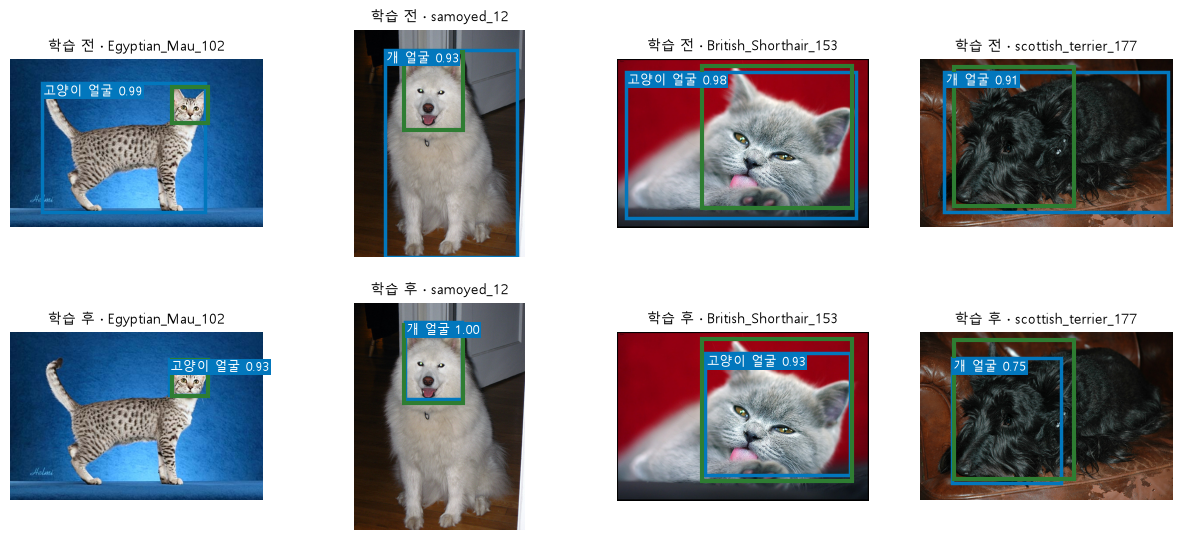

In [12]:
# 학습 전: COCO SSD 그대로 (cat · dog 번호만 우리 번호로)
coco_ssd = ssd300_vgg16(weights=SSD_W).to(device).eval()
COCO = SSD_W.meta["categories"]
to_ours = {COCO.index("cat"): 1, COCO.index("dog"): 2}
preds_coco = predict_all(coco_ssd, val_ids, label_map=to_ours)
preds_A = predict_all(model_best_A, val_ids)  # 학습 후: RUN_A best


# 같은 val 200장 · 같은 평가 함수
print(f"val {len(val_ids)}장 · 모델 안 신뢰도 하한 0.01로 모은 예측 · torchmetrics")
results = {"학습 전 COCO": evaluate(preds_coco),
           f"RUN_A best (epoch {best_A['epoch']})": evaluate(preds_A)}
for name, r in results.items():
    print(f"{name} | mAP50 {r['mAP50']:.4f} · mAP75 {r['mAP75']:.4f}"
          f" · mAP {r['mAP']:.4f} | AP50 고양이 {r['cat50']:.4f}"
          f" · 개 {r['dog50']:.4f}")


# 그림: 같은 val 사진 4장 · 신뢰도 0.5 이상만
picks = val_ids[::50][:4]
fig, axes = plt.subplots(2, 4, figsize=(15, 6.5))
for row, (name, preds) in enumerate((("학습 전", preds_coco),
                                     ("학습 후", preds_A))):
    by_id = {r["id"]: r for r in preds}
    for ax, s in zip(axes[row], picks):
        r = by_id[s]
        k = r["scores"] >= 0.5
        show(load_image(s), gt=make_target(s)["boxes"], pred=r["boxes"][k],
             labels=[f"{CLASSES[c]} {v:.2f}" for c, v in
                     zip(r["labels"][k].tolist(), r["scores"][k].tolist())],
             title=f"{name} · {s}", ax=ax)
plt.show()
del coco_ssd

**예측 정답** · 못 넘음 — `0.1169` (학습 후 `0.9448`), 몸 전체 박스는 머리 정답과 겹침이 작음 (객체탐지-1 7장)

**결과 해설**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">출력</th>
<th style="text-align: left;">의미</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>학습 전 COCO &#124; mAP50 0.1169 · mAP75 0.0094 · mAP 0.0342 &#124; AP50 고양이 0.1194 · 개 0.1144</code></td>
<td style="text-align: left;">몸 전체 박스 → 머리 정답과 맞지 않음</td>
</tr>
<tr>
<td style="text-align: left;"><code>RUN_A best (epoch 5) &#124; mAP50 0.9448 · mAP75 0.7884 · mAP 0.6738 &#124; AP50 고양이 0.9442 · 개 0.9453</code></td>
<td style="text-align: left;">같은 val · 같은 기준 · 머리 박스를 배움</td>
</tr>
<tr>
<td style="text-align: left;"><code>val 200장 · 모델 안 신뢰도 하한 0.01로 모은 예측 · torchmetrics</code></td>
<td style="text-align: left;">평가 조건을 결과와 함께 적음 (객체탐지-1 7장 한 문장)</td>
</tr>
</tbody>
</table>

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">학습 전 COCO SSD</td>
<td style="text-align: left;">몸 전체 박스 → 머리 정답과 안 맞음</td>
<td style="text-align: left;">기준선 (학습 효과 확인)</td>
</tr>
<tr>
<td style="text-align: left;">학습 후 RUN_A</td>
<td style="text-align: left;">머리 박스를 배움</td>
<td style="text-align: left;">비교 대상</td>
</tr>
<tr>
<td style="text-align: left;">mAP50 vs mAP@[.5:.95]</td>
<td style="text-align: left;">대략 맞음 vs 딱 맞음까지 (객체탐지-1 6-3)</td>
<td style="text-align: left;">둘 다 적기</td>
</tr>
<tr>
<td style="text-align: left;">클래스별 AP</td>
<td style="text-align: left;">고양이 · 개 따로</td>
<td style="text-align: left;">약한 클래스 찾기</td>
</tr>
</tbody>
</table>

> ⚠️ **주의** · mAP50은 0.94까지 올랐지만 mAP75는 0.79 → "거의 다 맞음"과 "딱 맞음"은 다름, 두 숫자를 함께 봐야 함

> ✅ **한 줄 정리** · 같은 val과 같은 평가 함수로 학습 전후를 비교하면, 우리 정답으로 다시 학습한 효과(mAP50 0.12 → 0.94)를 숫자로 확인할 수 있다.

**딥러닝 코드에서는** · 검증 루프에서 `predict_all` → `evaluate` 한 번으로 mAP50 · mAP75 · mAP · 클래스별 AP를 모두 기록 (계산 원리는 객체탐지-1 6장)

### 6-2. `A` 오류 분석 · 놓침 · 오탐 · 느슨한 박스 · 크기별 · `box_iou()` · `Counter()` <sub>Day02 D2-9</sub>

> 🎯 **남은 오류는 어떤 종류이고, 어떤 크기의 얼굴에서 많이 나오는가?**

💡 **쉽게 말하면** 시험 오답 노트를 **틀린 이유별로 분류**하는 것. 문제를 안 푼 것(놓침), 엉뚱한 답(오탐), 답은 맞는데 풀이가 엉성한 것(느슨한 박스)마다 대책이 다름.

**실행 흐름** · 사진마다 짝짓기 (객체탐지-1 5-1 규칙) → TP · FP · FN · 정밀도 · 재현율 → ① 놓침 크기 ② 오탐 점수 · 클래스 혼동 ③ 느슨한 박스 ④ 크기 구간별 찾은 비율 → 오류 사진

**먼저 예측** · 얼굴 크기 세 구간 중 IoU 0.5로 찾은 비율이 가장 낮은 구간은? — 답은 코드 실행 결과 아래에

RUN_A best · val · 신뢰도 0.5 · IoU 0.5 | TP 178 · FP 20 · FN 22 | 정밀도 0.899 · 재현율 0.890
① 놓침 22개 | 긴 변 100 미만 10개 | 가장 작은 5개: [31, 52, 53, 56, 57]
② 오탐 20개 | 점수 0.85 이상 4개 · 다른 클래스 얼굴에 친 박스(클래스 혼동) 9개
③ 느슨한 박스 21개 | 고양이 2 · 개 19
④ 긴 변 100 미만: 42개 | IoU 0.5로 찾음 32 (0.76) · 0.75로 찾음 26 (0.62)
④ 긴 변 100 ~ 200: 119개 | IoU 0.5로 찾음 109 (0.92) · 0.75로 찾음 100 (0.84)
④ 긴 변 200 이상: 39개 | IoU 0.5로 찾음 37 (0.95) · 0.75로 찾음 31 (0.79)


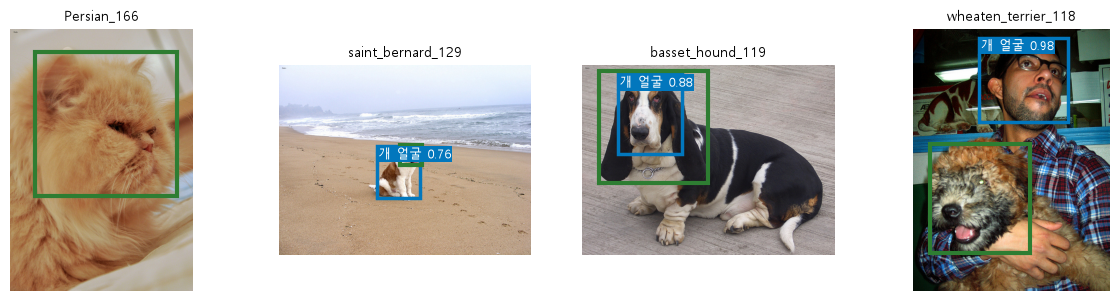

In [13]:
# 얼굴 크기 = 300×300으로 바뀐 뒤 긴 변 (객체탐지-1 2-4와 같은 정의)
def face_size(stem, box):
    size = ET.parse(XMLS / f"{stem}.xml").getroot().find("size")
    w, h = float(size.findtext("width")), float(size.findtext("height"))
    return max((box[2] - box[0]) / w * 300, (box[3] - box[1]) / h * 300)


# 사진 한 장 · 클래스마다 짝짓기 (객체탐지-1 5-1 규칙) → 판정 목록
def judge_image(r, score_thr=0.5, iou_thr=0.5):
    t, events = make_target(r["id"]), []
    for c in (1, 2):
        gts = t["boxes"][t["labels"] == c]
        keep = (r["labels"] == c) & (r["scores"] >= score_thr)
        boxes, scores = r["boxes"][keep], r["scores"][keep]  # 점수 높은 순
        ious = box_iou(boxes, gts)  # (예측 수, 정답 수)
        all_iou = box_iou(boxes, t["boxes"])  # 클래스 상관없이
        used = set()
        for i in range(len(boxes)):
            free = [(ious[i, j].item(), j) for j in range(len(gts))
                    if j not in used]
            best, j = max(free, default=(0.0, None))
            if j is not None and best >= iou_thr:
                used.add(j)
                events.append({"kind": "TP", "cls": c, "iou": best})
            else:  # FP: 다른 클래스 정답과 많이 겹쳤나 = 클래스 혼동
                mix = len(t["boxes"]) and all_iou[i].max().item() >= iou_thr
                events.append({"kind": "FP", "cls": c, "id": r["id"],
                               "score": scores[i].item(), "mix": bool(mix)})
        for j, g in enumerate(gts.tolist()):
            if j not in used:
                events.append({"kind": "FN", "cls": c, "id": r["id"],
                               "size": face_size(r["id"], g)})
    return events


ev_A = [e for r in preds_A for e in judge_image(r)]
k = Counter(e["kind"] for e in ev_A)
p, rc = k["TP"] / (k["TP"] + k["FP"]), k["TP"] / (k["TP"] + k["FN"])
print(f"RUN_A best · val · 신뢰도 0.5 · IoU 0.5 | TP {k['TP']} · FP {k['FP']}"
      f" · FN {k['FN']} | 정밀도 {p:.3f} · 재현율 {rc:.3f}")


# ① 놓침 (FN) · ② 오탐 (FP) · ③ 느슨한 박스 (TP 중 IoU 0.75 미만)
fn = [e for e in ev_A if e["kind"] == "FN"]
fp = [e for e in ev_A if e["kind"] == "FP"]
loose = [e for e in ev_A if e["kind"] == "TP" and e["iou"] < 0.75]
sizes_fn = sorted(round(e["size"]) for e in fn)
print(f"① 놓침 {len(fn)}개 | 긴 변 100 미만 {sum(v < 100 for v in sizes_fn)}개"
      f" | 가장 작은 5개: {sizes_fn[:5]}")
print(f"② 오탐 {len(fp)}개 | 점수 0.85 이상 {sum(e['score'] >= 0.85 for e in fp)}개"
      f" · 다른 클래스 얼굴에 친 박스(클래스 혼동) {sum(e['mix'] for e in fp)}개")
n_cat = sum(e["cls"] == 1 for e in loose)
print(f"③ 느슨한 박스 {len(loose)}개 | 고양이 {n_cat} · 개 {len(loose) - n_cat}")


# ④ 얼굴 크기별: 정답 얼굴마다 같은 클래스 예측(0.5 이상)과의 최대 IoU
def size_table(preds, score_thr=0.5):
    rows = []
    for r in preds:
        t = make_target(r["id"])
        for g, c in zip(t["boxes"], t["labels"]):
            keep = (r["labels"] == c) & (r["scores"] >= score_thr)
            best = 0.0
            if keep.any():
                best = box_iou(g[None], r["boxes"][keep]).max().item()
            rows.append((face_size(r["id"], g.tolist()), best))
    out = []
    for lo, hi, name in ((0, 100, "100 미만"), (100, 200, "100 ~ 200"),
                         (200, 301, "200 이상")):
        sel = [v for size, v in rows if lo <= size < hi]
        out.append((name, len(sel), sum(v >= 0.5 for v in sel),
                    sum(v >= 0.75 for v in sel)))
    return out


for name, n, f50, f75 in size_table(preds_A):
    print(f"④ 긴 변 {name}: {n}개 | IoU 0.5로 찾음 {f50} ({f50 / n:.2f})"
          f" · 0.75로 찾음 {f75} ({f75 / n:.2f})")


# 오류 사진 보기: 놓침 · 오탐 (최대 4장)
by_id = {r["id"]: r for r in preds_A}
err_ids = list(dict.fromkeys(e["id"] for e in fn + fp))[:4]
fig, axes = plt.subplots(1, 4, figsize=(15, 3.4))
for ax in axes:
    ax.axis("off")
for ax, s in zip(axes, err_ids):
    r = by_id[s]
    keep = r["scores"] >= 0.5
    show(load_image(s), gt=make_target(s)["boxes"], pred=r["boxes"][keep],
         labels=[f"{CLASSES[c]} {v:.2f}" for c, v in
                 zip(r["labels"][keep].tolist(), r["scores"][keep].tolist())],
         title=s, ax=ax)
plt.show()

**예측 정답** · 긴 변 100 미만 (`0.76`) — 작은 얼굴일수록 놓치고 덜 맞음

**결과 해설**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">출력</th>
<th style="text-align: left;">의미</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>RUN_A best · val · 신뢰도 0.5 · IoU 0.5 &#124; TP 178 · FP 20 · FN 22 &#124; 정밀도 0.899 · 재현율 0.890</code></td>
<td style="text-align: left;">신뢰도 0.5 한 자리의 성능</td>
</tr>
<tr>
<td style="text-align: left;"><code>① 놓침 22개 &#124; 긴 변 100 미만 10개 &#124; 가장 작은 5개: [31, 52, 53, 56, 57]</code></td>
<td style="text-align: left;">놓친 얼굴의 절반 가까이가 작은 얼굴</td>
</tr>
<tr>
<td style="text-align: left;"><code>② 오탐 20개 &#124; 점수 0.85 이상 4개 · 다른 클래스 얼굴에 친 박스(클래스 혼동) 9개</code></td>
<td style="text-align: left;">오탐의 절반은 고양이 ↔ 개를 헷갈린 것</td>
</tr>
<tr>
<td style="text-align: left;"><code>③ 느슨한 박스 21개 &#124; 고양이 2 · 개 19</code></td>
<td style="text-align: left;">개 얼굴 경계(귀 · 볼)가 덜 맞음 → 개 AP@[.5:.95]가 낮은 이유</td>
</tr>
<tr>
<td style="text-align: left;"><code>④ 긴 변 100 미만: 42개 &#124; IoU 0.5로 찾음 32 (0.76) · 0.75로 찾음 26 (0.62)</code></td>
<td style="text-align: left;">작은 얼굴이 가장 약함</td>
</tr>
<tr>
<td style="text-align: left;"><code>④ 긴 변 100 ~ 200: 119개 &#124; IoU 0.5로 찾음 109 (0.92) · 0.75로 찾음 100 (0.84)</code></td>
<td style="text-align: left;">중간 크기는 안정적</td>
</tr>
<tr>
<td style="text-align: left;"><code>④ 긴 변 200 이상: 39개 &#124; IoU 0.5로 찾음 37 (0.95) · 0.75로 찾음 31 (0.79)</code></td>
<td style="text-align: left;">큰 얼굴은 찾기는 쉽지만 딱 맞추기는 덜 됨</td>
</tr>
</tbody>
</table>

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">① 놓침 (FN)</td>
<td style="text-align: left;">찾지 못한 정답 얼굴</td>
<td style="text-align: left;">작은 얼굴 · 특이한 자세 확인</td>
</tr>
<tr>
<td style="text-align: left;">② 오탐 (FP)</td>
<td style="text-align: left;">엉뚱한 자리 · 클래스 혼동 · 중복</td>
<td style="text-align: left;">점수 높은 FP부터 사진으로</td>
</tr>
<tr>
<td style="text-align: left;">③ 느슨한 박스</td>
<td style="text-align: left;">TP지만 IoU 0.5 ~ 0.75</td>
<td style="text-align: left;">AP75 · mAP가 낮은 이유</td>
</tr>
<tr>
<td style="text-align: left;">④ 크기별</td>
<td style="text-align: left;">얼굴 긴 변 구간마다 찾은 비율</td>
<td style="text-align: left;">작은 물체 약점 확인</td>
</tr>
<tr>
<td style="text-align: left;">숫자 vs 사진</td>
<td style="text-align: left;">mAP는 얼마나, 사진은 어디서 · 왜</td>
<td style="text-align: left;">둘 다 보고 가설 세우기</td>
</tr>
</tbody>
</table>

> ⚠️ **주의** · mAP 하나로는 어디서 틀리는지 알 수 없음 → 오류를 종류 · 크기로 나누고 사진으로 확인한 뒤 가설을 세움 (예: 작은 얼굴 → 축소 증강 · 입력 크기)

> ✅ **한 줄 정리** · 오류를 놓침 · 오탐 · 느슨한 박스 · 크기별로 나누면, 숫자(mAP)가 알려 주지 않는 약점과 다음 실험의 방향이 보인다.

**딥러닝 코드에서는** · 관찰 → 가설 → 한 가지만 바꿔 다시 학습 → 같은 val로 비교 (7장 RUN_B) — 강의 D2-9 · D2-10의 흐름

#### 6장 정리 · 소속별 최종 요약표

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">함수·문법</th>
<th style="text-align: left;">소속</th>
<th style="text-align: left;">역할</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>MeanAveragePrecision(class_metrics=True)</code></td>
<td style="text-align: left;">torchmetrics.detection</td>
<td style="text-align: left;">mAP · 클래스별 AP</td>
</tr>
<tr>
<td style="text-align: left;"><code>judge_image(r)</code></td>
<td style="text-align: left;">직접 만든 함수</td>
<td style="text-align: left;">사진 한 장의 TP · FP · FN (객체탐지-1 5-1 규칙)</td>
</tr>
<tr>
<td style="text-align: left;"><code>size_table(preds)</code></td>
<td style="text-align: left;">직접 만든 함수</td>
<td style="text-align: left;">얼굴 크기 구간별 찾은 비율</td>
</tr>
<tr>
<td style="text-align: left;"><code>box_iou()</code></td>
<td style="text-align: left;">torchvision.ops</td>
<td style="text-align: left;">IoU 표 (객체탐지-1 3장)</td>
</tr>
</tbody>
</table>

---
## 7. 종합 실습 · 뒤집기 증강 없음 vs 있음

> **연결** · 1~6장을 모두 사용. 강의 D2-10 · D2-11처럼 **딱 한 가지(train 좌우 뒤집기)만 바꾼** RUN_B를 학습해 같은 val · 같은 평가 함수로 RUN_A와 비교하고, test를 보기 전에 정한 규칙으로 최종 모델을 골라 test 200장에 한 번 채점

**흐름 위치** · ⑤ 학습(RUN_B) → ⑥ 평가(mAP · 클래스별 AP · 오류 유형) → 고르기 → test 한 번 → ⑦ 결과 한 문장

> 🎯 **좌우 뒤집기 하나만 바꾼 두 학습 중 무엇이 나으며, 그 차이를 뒤집기 덕분이라고 말할 수 있는가?**

💡 **쉽게 말하면** 같은 학생 둘에게 같은 교재로 공부시키되 한 명에게만 **거울에 비친 문제**도 섞어 주고, 같은 모의고사로 비교하는 것. 점수 차이가 작으면 운인지 방법 덕분인지 한 번의 시험으로는 가리기 어려움.

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">단계</th>
<th style="text-align: left;">하는 일</th>
<th style="text-align: left;">쓰는 섹션</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">1</td>
<td style="text-align: left;">RUN_B 학습 (<code>flip=True</code>) · 나머지 설정은 RUN_A와 같음</td>
<td style="text-align: left;">2-1 · 5-1</td>
</tr>
<tr>
<td style="text-align: left;">2</td>
<td style="text-align: left;">같은 epoch끼리 val mAP 비교 · 그래프</td>
<td style="text-align: left;">5-1</td>
</tr>
<tr>
<td style="text-align: left;">3</td>
<td style="text-align: left;">두 best를 같은 val로: mAP50 · mAP75 · mAP · 클래스별 AP · 오류 유형</td>
<td style="text-align: left;">6-1 · 6-2</td>
</tr>
<tr>
<td style="text-align: left;">4</td>
<td style="text-align: left;">고르는 규칙(먼저 정함): 세 지표 모두 높으면 그쪽, 엇갈리면 mAP@[.5:.95]</td>
<td style="text-align: left;">강의 D2-11</td>
</tr>
<tr>
<td style="text-align: left;">5</td>
<td style="text-align: left;">고른 모델로 test 200장에 한 번</td>
<td style="text-align: left;">1-1</td>
</tr>
</tbody>
</table>

**먼저 예측** · 뒤집기를 켠 RUN_B가 val mAP@[.5:.95]에서 RUN_A보다 높을까? — 답은 코드 실행 결과 아래에

[RUN_B] epoch 1 | lr 1e-03 | 손실 6.392 | val mAP50 0.3911 · mAP 0.1901


[RUN_B] epoch 2 | lr 1e-03 | 손실 3.489 | val mAP50 0.8631 · mAP 0.4650


[RUN_B] epoch 3 | lr 1e-03 | 손실 2.471 | val mAP50 0.9229 · mAP 0.5972


[RUN_B] epoch 4 | lr 1e-03 | 손실 1.880 | val mAP50 0.9192 · mAP 0.5717


[RUN_B] epoch 5 | lr 1e-04 | 손실 1.515 | val mAP50 0.9475 · mAP 0.6699
[RUN_B] 학습 시간 약 17분 (컴퓨터마다 다름)
epoch | val mAP  A · B | val mAP50  A · B
  1   | 0.2401 · 0.1901 | 0.4676 · 0.3911
  2   | 0.4910 · 0.4650 | 0.8573 · 0.8631
  3   | 0.6078 · 0.5972 | 0.9385 · 0.9229
  4   | 0.6522 · 0.5717 | 0.9494 · 0.9192
  5   | 0.6738 · 0.6699 | 0.9448 · 0.9475


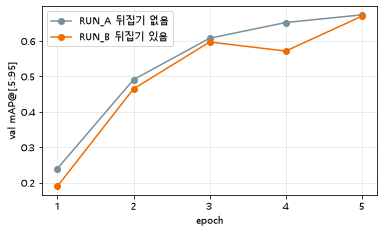

In [14]:
# RUN_B: RUN_A와 딱 하나만 다름 (train 좌우 뒤집기 p = 0.5)
model_B, hist_B = fit("RUN_B", flip=True)


# 같은 epoch끼리 val mAP 비교
print("epoch | val mAP  A · B | val mAP50  A · B")
for a, b in zip(hist_A, hist_B):
    print(f"  {a['epoch']}   | {a['mAP']:.4f} · {b['mAP']:.4f} |"
          f" {a['mAP50']:.4f} · {b['mAP50']:.4f}")
fig, ax = plt.subplots(figsize=(6, 3.4))
for name, h, color in (("RUN_A 뒤집기 없음", hist_A, "#78909c"),
                       ("RUN_B 뒤집기 있음", hist_B, "#ef6c00")):
    ax.plot([e["epoch"] for e in h], [e["mAP"] for e in h], "o-",
            color=color, label=name)
ax.set(xlabel="epoch", ylabel="val mAP@[.5:.95]", xticks=range(1, EPOCHS + 1))
ax.legend()
ax.grid(alpha=0.3)
plt.show()

In [15]:
# 두 best 모델을 같은 val로 채점: mAP · 클래스별 AP · 오류 유형
best_B = torch.load(CKPT_DIR / "RUN_B_best.pt", map_location="cpu",
                    weights_only=False)
model_best_B = make_ssd()
model_best_B.load_state_dict(best_B["model"])
model_best_B = model_best_B.to(device).eval()
preds_B = predict_all(model_best_B, val_ids)

summary = {}
runs = (("RUN_A", preds_A, best_A), ("RUN_B", preds_B, best_B))
for name, preds, ck in runs:
    r = evaluate(preds)
    ev = [e for p in preds for e in judge_image(p)]
    k = Counter(e["kind"] for e in ev)
    loose = sum(e["kind"] == "TP" and e["iou"] < 0.75 for e in ev)
    _, n_small, f50, f75 = size_table(preds)[0]  # 긴 변 100 미만
    summary[name] = r
    print(f"{name} best epoch {ck['epoch']} | mAP50 {r['mAP50']:.4f} · "
          f"mAP75 {r['mAP75']:.4f} · mAP {r['mAP']:.4f}")
    print(f"   클래스별 AP50 고양이 {r['cat50']:.4f} · 개 {r['dog50']:.4f} |"
          f" AP 고양이 {r['cat']:.4f} · 개 {r['dog']:.4f}")
    print(f"   놓침 {k['FN']} · 오탐 {k['FP']} · 느슨한 박스 {loose} |"
          f" 작은 얼굴 {n_small}개 중 0.75로 찾음 {f75}")


# 최종 모델 고르는 규칙 (test 보기 전에 정함): 세 지표 모두 높으면 그쪽,
# 엇갈리면 mAP@[.5:.95]가 높은 쪽
keys = ("mAP50", "mAP75", "mAP")
b_wins = [summary["RUN_B"][k] > summary["RUN_A"][k] for k in keys]
if all(b_wins) or not any(b_wins):
    final = "RUN_B" if all(b_wins) else "RUN_A"
else:
    final = max(summary, key=lambda n: summary[n]["mAP"])
print("B가 높은가 (mAP50, mAP75, mAP):", b_wins, "→ 최종:", final)


# 처음 보는 test 200장에 한 번 (결과를 보고 다시 고르지 않음)
final_model = model_best_B if final == "RUN_B" else model_best_A
preds_test = predict_all(final_model, test_ids)
r = evaluate(preds_test)
ev = [e for p in preds_test for e in judge_image(p)]
k = Counter(e["kind"] for e in ev)
print(f"test {len(test_ids)}장 · {final} | mAP50 {r['mAP50']:.4f} · mAP75"
      f" {r['mAP75']:.4f} · mAP {r['mAP']:.4f} | 신뢰도 0.5: TP {k['TP']}"
      f" · FP {k['FP']} · FN {k['FN']}")

RUN_A best epoch 5 | mAP50 0.9448 · mAP75 0.7884 · mAP 0.6738
   클래스별 AP50 고양이 0.9442 · 개 0.9453 | AP 고양이 0.7296 · 개 0.6180
   놓침 22 · 오탐 20 · 느슨한 박스 21 | 작은 얼굴 42개 중 0.75로 찾음 26


RUN_B best epoch 5 | mAP50 0.9475 · mAP75 0.7763 · mAP 0.6699
   클래스별 AP50 고양이 0.9449 · 개 0.9501 | AP 고양이 0.7298 · 개 0.6100
   놓침 19 · 오탐 20 · 느슨한 박스 27 | 작은 얼굴 42개 중 0.75로 찾음 27
B가 높은가 (mAP50, mAP75, mAP): [True, False, False] → 최종: RUN_A


test 200장 · RUN_A | mAP50 0.9799 · mAP75 0.8437 · mAP 0.6909 | 신뢰도 0.5: TP 190 · FP 8 · FN 10


**예측 정답** · 아님 — RUN_A `0.6738` · RUN_B `0.6699`, mAP50만 B가 조금 높고(0.9475 > 0.9448) mAP75 · mAP는 A가 높아 규칙에 따라 **RUN_A** 선택

**결과 해설**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">출력</th>
<th style="text-align: left;">의미</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>[RUN_B] epoch 1 &#124; lr 1e-03 &#124; 손실 6.392 &#124; val mAP50 0.3911 · mAP 0.1901</code></td>
<td style="text-align: left;">같은 출발점 · 같은 섞는 순서, 뒤집힌 사진이 섞여 첫 epoch는 A(0.2401)보다 낮음</td>
</tr>
<tr>
<td style="text-align: left;"><code>[RUN_B] epoch 4 &#124; lr 1e-03 &#124; 손실 1.880 &#124; val mAP50 0.9192 · mAP 0.5717</code></td>
<td style="text-align: left;">epoch 4에서 한 번 내려감 → 짧은 학습에서는 epoch마다 흔들림</td>
</tr>
<tr>
<td style="text-align: left;"><code>[RUN_B] epoch 5 &#124; lr 1e-04 &#124; 손실 1.515 &#124; val mAP50 0.9475 · mAP 0.6699</code></td>
<td style="text-align: left;">lr을 줄인 마지막 epoch가 best</td>
</tr>
<tr>
<td style="text-align: left;"><code>5   &#124; 0.6738 · 0.6699 &#124; 0.9448 · 0.9475</code></td>
<td style="text-align: left;">같은 epoch 5끼리: mAP는 A, mAP50은 B → 엇갈림</td>
</tr>
<tr>
<td style="text-align: left;"><code>RUN_A best epoch 5 &#124; mAP50 0.9448 · mAP75 0.7884 · mAP 0.6738</code></td>
<td style="text-align: left;">엄격한 기준(mAP75 · mAP)은 A가 높음</td>
</tr>
<tr>
<td style="text-align: left;"><code>RUN_B best epoch 5 &#124; mAP50 0.9475 · mAP75 0.7763 · mAP 0.6699</code></td>
<td style="text-align: left;">대략 맞히기(mAP50)는 B가 조금 높음</td>
</tr>
<tr>
<td style="text-align: left;"><code>놓침 22 · 오탐 20 · 느슨한 박스 21 &#124; 작은 얼굴 42개 중 0.75로 찾음 26</code></td>
<td style="text-align: left;">RUN_A 오류 (6-2와 같은 수)</td>
</tr>
<tr>
<td style="text-align: left;"><code>놓침 19 · 오탐 20 · 느슨한 박스 27 &#124; 작은 얼굴 42개 중 0.75로 찾음 27</code></td>
<td style="text-align: left;">RUN_B: 놓침은 줄었지만 느슨한 박스가 늘어 mAP75가 낮아짐</td>
</tr>
<tr>
<td style="text-align: left;"><code>B가 높은가 (mAP50, mAP75, mAP): [True, False, False] → 최종: RUN_A</code></td>
<td style="text-align: left;">규칙: 엇갈리면 mAP@[.5:.95]가 높은 쪽</td>
</tr>
<tr>
<td style="text-align: left;"><code>test 200장 · RUN_A &#124; mAP50 0.9799 · mAP75 0.8437 · mAP 0.6909 &#124; 신뢰도 0.5: TP 190 · FP 8 · FN 10</code></td>
<td style="text-align: left;">처음 보는 test에 한 번 · val(0.6738)과 비슷한 수준 → 고르는 과정에서 val에 과하게 맞추지 않았음</td>
</tr>
</tbody>
</table>

**개선 기록 6칸** (강의 D2-10 형식)

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">칸</th>
<th style="text-align: left;">RUN_A → RUN_B</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">무엇을 바꿨나</td>
<td style="text-align: left;">train 사진만 확률 0.5로 좌우 뒤집기 (박스 같이) · 나머지 설정 같음</td>
</tr>
<tr>
<td style="text-align: left;">왜</td>
<td style="text-align: left;">같은 얼굴의 왼쪽 · 오른쪽 모습을 더 보게 해 일반화를 돕기 위해 (오류 분석 전에 미리 정한 변경)</td>
</tr>
<tr>
<td style="text-align: left;">전 (RUN_A best · val)</td>
<td style="text-align: left;">mAP50 0.9448 · mAP75 0.7884 · mAP 0.6738</td>
</tr>
<tr>
<td style="text-align: left;">후 (RUN_B best · val)</td>
<td style="text-align: left;">mAP50 0.9475 · mAP75 0.7763 · mAP 0.6699</td>
</tr>
<tr>
<td style="text-align: left;">말할 수 있는 것</td>
<td style="text-align: left;">이 두 학습 · 이 val에서 놓침은 22 → 19로 줄고 느슨한 박스는 21 → 27로 늘었으며, 고르는 규칙에 따라 RUN_A를 골랐다</td>
</tr>
<tr>
<td style="text-align: left;">말할 수 없는 것</td>
<td style="text-align: left;">뒤집기가 도움이 안 된다 · 해가 된다 (600장 · 5 epoch · 학습 한 번씩이라 차이 0.004는 흔들림 안일 수 있음, 강의는 2569장 · 10 epoch에서 B가 높았음)</td>
</tr>
</tbody>
</table>

**결과를 적는 한 문장** · 정답 있는 trainval에서 품종 층화로 나눈 train 600 · val 200 · test 200장, SSD300(COCO) 분류 헤드 3칸 교체, SGD lr 0.001 · 5 epoch(4 이후 1/10), best = val mAP@[.5:.95] → RUN_A(뒤집기 없음) best epoch 5 · test mAP50 0.9799 · mAP75 0.8437 · mAP@[.5:.95] 0.6909 (torchmetrics · 신뢰도 하한 0.01) · 신뢰도 0.5에서 TP 190 · FP 8 · FN 10

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">한 가지만 바꾼 비교 (RUN_A vs RUN_B)</td>
<td style="text-align: left;">차이의 원인을 그 한 가지로 좁힐 수 있음</td>
<td style="text-align: left;">증강 · lr · 모델 크기 실험 (기본)</td>
</tr>
<tr>
<td style="text-align: left;">여러 가지를 한꺼번에 바꾸기</td>
<td style="text-align: left;">좋아져도 무엇 덕분인지 모름</td>
<td style="text-align: left;">쓰지 않음</td>
</tr>
<tr>
<td style="text-align: left;">best epoch끼리 vs 같은 epoch끼리</td>
<td style="text-align: left;">각자 가장 좋은 때 vs 같은 학습량</td>
<td style="text-align: left;">둘 다 보고 판단</td>
</tr>
<tr>
<td style="text-align: left;">val로 고르기 vs test로 고르기</td>
<td style="text-align: left;">고르기는 val, test는 마지막 한 번</td>
<td style="text-align: left;">test를 보고 바꾸면 test가 val이 됨</td>
</tr>
<tr>
<td style="text-align: left;">학습 한 번 vs 여러 seed</td>
<td style="text-align: left;">한 번은 흔들림을 모름 vs 평균 · 범위로 판단</td>
<td style="text-align: left;">차이가 작을 때는 seed를 바꿔 반복</td>
</tr>
</tbody>
</table>

> ⚠️ **주의** · val 차이가 0.004처럼 작으면 seed · epoch에 따라 순위가 바뀔 수 있음 → 결론은 "이 조건에서"로 한정하고, 확실히 하려면 seed를 바꿔 여러 번 학습

> ✅ **한 줄 정리** · 한 가지만 바꾼 두 학습을 같은 val · 같은 평가 함수로 비교하고, 미리 정한 규칙으로 고른 모델을 test에 한 번만 채점하면 결과를 정직하게 말할 수 있다.

**딥러닝 코드에서는** · 실험마다 `config`(무엇을 바꿨나) · `history`(epoch별 val) · best 체크포인트 · test 결과를 함께 저장 → 객체탐지-3에서는 ultralytics가 `runs/`에 같은 것을 자동으로 남김

---
## 8. 백지 복습

위 내용을 **보지 않고** 답한 뒤, ✅ 한 줄 정리와 비교해 ○ (정확) · △ (일부) · × (모름)를 표시. △ · ×인 섹션만 다시 보기.

### 8-1. 질문에 답하기

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">섹션</th>
<th style="text-align: left;">🎯 질문</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">1-1</td>
<td style="text-align: left;">val과 test는 각각 언제 쓰는가?</td>
</tr>
<tr>
<td style="text-align: left;">1-2</td>
<td style="text-align: left;">탐지 Dataset의 <code>ds[i]</code>는 무엇을 돌려주는가?</td>
</tr>
<tr>
<td style="text-align: left;">1-3</td>
<td style="text-align: left;">탐지 DataLoader에 <code>collate_fn</code>이 필요한 이유는?</td>
</tr>
<tr>
<td style="text-align: left;">2-1</td>
<td style="text-align: left;">사진만 뒤집으면 왜 에러 없이 틀리는가?</td>
</tr>
<tr>
<td style="text-align: left;">3-1</td>
<td style="text-align: left;"><code>num_classes = 3</code>만 바꾸면 무엇이 문제인가?</td>
</tr>
<tr>
<td style="text-align: left;">3-2</td>
<td style="text-align: left;">SSD와 Faster R-CNN은 헤드 교체에서 바꾸는 층이 어떻게 다른가?</td>
</tr>
<tr>
<td style="text-align: left;">4-1</td>
<td style="text-align: left;">스모크 테스트의 확인 두 가지는?</td>
</tr>
<tr>
<td style="text-align: left;">4-2</td>
<td style="text-align: left;">train 모드와 eval 모드의 출력은?</td>
</tr>
<tr>
<td style="text-align: left;">5-1</td>
<td style="text-align: left;"><code>scheduler.step()</code>은 어디서 부르는가?</td>
</tr>
<tr>
<td style="text-align: left;">5-2</td>
<td style="text-align: left;">last와 best 체크포인트에는 각각 무엇이 들어 있고 언제 쓰는가?</td>
</tr>
<tr>
<td style="text-align: left;">6-1</td>
<td style="text-align: left;">학습 전후를 공정하게 비교하려면 무엇을 같게 하는가?</td>
</tr>
<tr>
<td style="text-align: left;">6-2</td>
<td style="text-align: left;">오류 분석의 네 가지 관점은?</td>
</tr>
<tr>
<td style="text-align: left;">7</td>
<td style="text-align: left;">두 학습의 차이를 말할 때 "말할 수 없는 것"을 적는 이유는?</td>
</tr>
</tbody>
</table>

#### 내 답 · 이 셀을 더블클릭해서 작성

**1-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**1-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**1-3** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**2-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**3-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**3-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**4-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**4-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**5-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**5-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**6-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**6-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**7** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

### 8-2. 코드로 답하기

모델 없이 텐서 · 숫자만으로 확인. 아래 빈 셀에 직접 작성 후 실행.

1. 크기가 다른 이미지 2장 `(3, 4, 5)` · `(3, 6, 2)`와 target 2개를 `collate_fn`으로 묶어 이미지 목록의 모양 출력
2. 폭 600 사진의 박스 `[[333., 72., 425., 158.]]`을 좌우로 뒤집은 박스와, 두 번 뒤집으면 원래와 같은지
3. SSD 첫 특징 맵(칸마다 디폴트 박스 4개)의 분류 층 출력 채널: COCO 91칸일 때 · 3칸일 때
4. lr 0.001 · `StepLR(step_size=2, gamma=0.1)`를 epoch 끝마다 부를 때 epoch 1 ~ 5의 lr
5. TP 178 · FP 20 · FN 22일 때 정밀도 · 재현율 (소수 셋째 자리)

In [16]:
# 8-2 직접 작성

### 8-3. 모범 답안 · 8-1 · 8-2를 다 쓴 뒤에 보기

#### 8-1 답

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">섹션</th>
<th style="text-align: left;">답</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">1-1</td>
<td style="text-align: left;">val = 모델 · epoch · 설정 고르기, test = 다 고른 뒤 마지막에 한 번</td>
</tr>
<tr>
<td style="text-align: left;">1-2</td>
<td style="text-align: left;">(이미지 [3, H, W] 0~1, {boxes float32 [N, 4], labels int64 [N]})</td>
</tr>
<tr>
<td style="text-align: left;">1-3</td>
<td style="text-align: left;">사진 크기 · 박스 수가 달라 기본 묶기(stack)가 실패 → 목록으로 묶음</td>
</tr>
<tr>
<td style="text-align: left;">2-1</td>
<td style="text-align: left;">박스 숫자는 여전히 사진 안 · x1 &lt; x2라 점검을 통과하지만, 얼굴이 없는 자리를 가리킴</td>
</tr>
<tr>
<td style="text-align: left;">3-1</td>
<td style="text-align: left;">층은 만들 때의 91칸 그대로라 점수 모양이 안 바뀌고, 에러 없이 우리 1번을 COCO person 칸으로 학습</td>
</tr>
<tr>
<td style="text-align: left;">3-2</td>
<td style="text-align: left;">SSD = 분류 헤드(<code>SSDClassificationHead</code>)만, Faster R-CNN = 분류 + 클래스별 박스 보정(<code>FastRCNNPredictor</code>)</td>
</tr>
<tr>
<td style="text-align: left;">4-1</td>
<td style="text-align: left;">클래스 점수 마지막 칸 = 클래스 수, 몇 step 학습해 손실이 유한하고 내려가는지</td>
</tr>
<tr>
<td style="text-align: left;">4-2</td>
<td style="text-align: left;">train 모드 + 정답 = 손실 dict, eval 모드 + 사진 = 사진마다 예측 dict의 list</td>
</tr>
<tr>
<td style="text-align: left;">5-1</td>
<td style="text-align: left;">(StepLR이면) epoch 끝마다 한 번. 안 부르면 lr 그대로, batch마다 부르면 lr이 순식간에 0</td>
</tr>
<tr>
<td style="text-align: left;">5-2</td>
<td style="text-align: left;">last = 모델 · optimizer · scheduler (이어 학습), best = val 점수가 가장 높은 가중치 (평가 · 배포)</td>
</tr>
<tr>
<td style="text-align: left;">6-1</td>
<td style="text-align: left;">같은 val 사진 · 같은 평가 함수 · 같은 신뢰도 하한 · 같은 클래스 번호</td>
</tr>
<tr>
<td style="text-align: left;">6-2</td>
<td style="text-align: left;">놓침(FN) · 오탐(FP) · 느슨한 박스(TP 중 IoU 0.5 ~ 0.75) · 크기별</td>
</tr>
<tr>
<td style="text-align: left;">7</td>
<td style="text-align: left;">학습 한 번 · 작은 데이터 · 작은 차이는 흔들림일 수 있어 결론이 과장되지 않게 하려고</td>
</tr>
</tbody>
</table>

#### 8-2 답

```python
# 1. collate_fn: 쌓지 않고 목록 두 개로
batch = [(torch.zeros(3, 4, 5), {"labels": torch.tensor([1])}),
         (torch.zeros(3, 6, 2), {"labels": torch.tensor([2, 2])})]
images, targets = tuple(zip(*batch))
print([tuple(im.shape) for im in images])  # [(3, 4, 5), (3, 6, 2)]

# 2. x1' = W - x2, x2' = W - x1 → 두 번이면 원래
b, W = torch.tensor([[333., 72., 425., 158.]]), 600
f = b.clone()
f[:, 0], f[:, 2] = W - b[:, 2], W - b[:, 0]
g = f.clone()
g[:, 0], g[:, 2] = W - f[:, 2], W - f[:, 0]
print(f.tolist(), torch.equal(g, b))  # [[175.0, 72.0, 267.0, 158.0]] True

# 3. 출력 채널 = 칸마다 박스 수 × 클래스 수
print(4 * 91, 4 * 3)  # 364 12

# 4. epoch 끝마다 step() → 2 epoch마다 1/10
w = torch.nn.Parameter(torch.zeros(1))
opt = torch.optim.SGD([w], lr=0.001)
sch = torch.optim.lr_scheduler.StepLR(opt, step_size=2, gamma=0.1)
lrs = []
for _ in range(5):
    lrs.append(f"{opt.param_groups[0]['lr']:.0e}")
    opt.step()
    sch.step()
print(lrs)  # ['1e-03', '1e-03', '1e-04', '1e-04', '1e-05']

# 5. 정밀도 = TP ÷ (TP + FP), 재현율 = TP ÷ (TP + FN)
tp, fp, fn = 178, 20, 22
print(round(tp / (tp + fp), 3), round(tp / (tp + fn), 3))  # 0.899 0.89
```

---
## 9. 면접 30초 답변

**Q1. 사전학습 탐지 모델을 내 데이터 클래스에 맞게 바꾸는 방법은?**
> 몸통과 위치 관련 층은 COCO 학습값을 그대로 두고, 클래스 수가 들어간 마지막 판정 층만 새로 만들어 끼웁니다. SSD는 분류 헤드를 `SSDClassificationHead`로, Faster R-CNN은 `box_predictor`를 `FastRCNNPredictor(1024, 클래스 수)`로 바꾸며, 클래스 수에는 배경을 포함합니다. 숫자 속성만 바꾸면 층이 그대로라 에러 없이 틀리므로, 학습 전에 출력 모양을 확인합니다.

**Q2. 탐지 DataLoader에서 collate_fn을 쓰는 이유는?**
> 탐지 데이터는 사진 크기와 물체 수가 사진마다 달라 기본 묶기 함수가 한 텐서로 쌓지 못합니다. 그래서 `tuple(zip(*batch))`로 이미지 목록과 target 딕셔너리 목록을 따로 묶고, torchvision 탐지 모델은 이 목록을 그대로 받아 안에서 크기를 맞춥니다.

**Q3. 탐지 데이터 증강에서 주의할 점은?**
> 사진의 기하 변환은 박스에도 똑같이 적용해야 합니다. 좌우 뒤집기는 x1과 x2를 폭에서 빼고 서로 바꾸며, train에만 확률적으로 적용하고 val과 test는 고정합니다. 사진만 뒤집으면 숫자 점검을 통과해 에러 없이 정답이 틀어지므로, 두 번 뒤집어 원래와 같은지와 그림으로 확인합니다.

**Q4. 학습 중 어떤 체크포인트를 저장하고 무엇으로 고르나요?**
> 매 epoch 마지막 상태를 모델 · optimizer · scheduler와 함께 last로 저장해 이어서 학습할 수 있게 하고, val mAP가 가장 높을 때의 가중치를 best로 따로 저장합니다. 평가와 배포는 best로 하고, test는 고르는 규칙을 정한 뒤 마지막에 한 번만 씁니다.

**Q5. mAP가 나온 뒤 성능을 어떻게 더 올리나요?**
> 오류를 놓침 · 오탐 · 느슨한 박스 · 물체 크기별로 나눠 사진으로 확인하고, 예를 들어 작은 물체를 많이 놓치면 축소 증강이나 입력 크기를 키우는 가설을 세웁니다. 그다음 한 가지만 바꿔 다시 학습하고 같은 val과 평가 함수로 비교하며, 차이가 작으면 seed를 바꿔 반복해 흔들림인지 확인합니다.

---
## 10. 전체 코드

1~7장 핵심 흐름(나누기 → Dataset · 뒤집기 → collate_fn → 헤드 교체 → 학습 1 epoch → 체크포인트 → val mAP)을 한 셀에 모음. **0장 준비 셀을 실행한 뒤 이 셀만 실행해도 동작**하며, 학습은 시간을 줄이려고 1 epoch만 함. 같은 seed · 같은 설정(뒤집기 켬)이라 `[6]` 값이 7장 RUN_B epoch 1의 val 점수와 같으면 재현 성공.

In [17]:
# 1~7장 핵심 흐름 한 셀 (0장 준비 셀을 먼저 실행 · 학습 1 epoch만)
from torchvision.models.detection import SSD300_VGG16_Weights, ssd300_vgg16
from torchvision.models.detection.ssd import SSDClassificationHead


def read_list(name):
    return [line.split()[0] for line in open(ANN / name)
            if line.strip() and not line.startswith("#")]


# [1] 나누기 · Dataset · collate_fn
xml_stems = {p.stem for p in XMLS.glob("*.xml")}
pool = [s for s in read_list("trainval.txt") if s in xml_stems]
breeds = [s.rsplit("_", 1)[0] for s in pool]
tr, rest = train_test_split(pool, train_size=600, test_size=400,
                            stratify=breeds, random_state=42)
va = train_test_split(rest, test_size=200, random_state=42,
                      stratify=[s.rsplit("_", 1)[0] for s in rest])[0]


class Faces(Dataset):
    def __init__(self, ids, flip=False):
        self.ids, self.flip = ids, flip
        self.gen = torch.Generator().manual_seed(1)

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, i):
        stem = self.ids[i]
        img, t = TF.to_tensor(load_image(stem)), make_target(stem)
        if self.flip and torch.rand(1, generator=self.gen) < 0.5:  # [2]
            b, W = t["boxes"].clone(), img.shape[-1]
            b[:, 0], b[:, 2] = W - t["boxes"][:, 2], W - t["boxes"][:, 0]
            img, t = img.flip(-1), {**t, "boxes": b}
        return img, t


loader = DataLoader(Faces(tr, flip=True), batch_size=16, shuffle=True,
                    collate_fn=lambda batch: tuple(zip(*batch)),
                    generator=torch.Generator().manual_seed(0))

# [3] 분류 헤드 교체 (91칸 → 3칸)
torch.manual_seed(0)
model = ssd300_vgg16(weights=SSD300_VGG16_Weights.COCO_V1)
old = model.head.classification_head
model.head.classification_head = SSDClassificationHead(
    [c.in_channels for c in old.module_list],
    model.anchor_generator.num_anchors_per_location(), 3)
model = model.to(device)

# [4 · 5] 학습 1 epoch (train 모드 = 손실 dict)
opt = torch.optim.SGD(model.parameters(), lr=0.001, momentum=0.9,
                      weight_decay=5e-4)
model.train()
for images, targets in loader:
    loss = sum(model([x.to(device) for x in images],
                     [{k: v.to(device) for k, v in t.items()}
                      for t in targets]).values())
    opt.zero_grad()
    loss.backward()
    opt.step()
torch.save({"model": model.state_dict()}, CKPT_DIR / "all_cell.pt")

# [6] val mAP (eval 모드 = 사진마다 예측 dict)
model.eval()
metric = MeanAveragePrecision()
metric.warn_on_many_detections = False
for k in range(0, len(va), 16):
    with torch.no_grad():
        outs = model([TF.to_tensor(load_image(s)).to(device)
                      for s in va[k:k + 16]])
    metric.update([{k2: v.cpu() for k2, v in o.items()} for o in outs],
                  [make_target(s) for s in va[k:k + 16]])
r = metric.compute()
print("[6] 1 epoch · val mAP50", round(r["map_50"].item(), 4),
      "· mAP", round(r["map"].item(), 4))

[6] 1 epoch · val mAP50 0.3911 · mAP 0.1901


---
## 11. 전체 최종 요약표

### 등급별 핵심

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: center;">등급</th>
<th style="text-align: left;">주제</th>
<th style="text-align: left;">반드시 기억할 것</th>
<th style="text-align: left;">딥러닝 코드에서</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">나누기</td>
<td style="text-align: left;">정답 있는 사진을 층화로 train · val · test, test는 마지막 한 번</td>
<td style="text-align: left;"><code>train_test_split(stratify=)</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">탐지 Dataset</td>
<td style="text-align: left;">(이미지, {boxes, labels}) · 사진 크기 제각각</td>
<td style="text-align: left;"><code>__getitem__</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">collate_fn</td>
<td style="text-align: left;">쌓지 말고 목록 두 개</td>
<td style="text-align: left;"><code>collate_fn=lambda b: tuple(zip(*b))</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">박스 증강</td>
<td style="text-align: left;">사진과 박스를 함께 · train에만</td>
<td style="text-align: left;"><code>x1' = W - x2</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">헤드 교체</td>
<td style="text-align: left;">숫자만 바꾸지 말고 층을 새로 · 클래스 수는 배경 포함</td>
<td style="text-align: left;"><code>SSDClassificationHead</code> · <code>FastRCNNPredictor</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">스모크 테스트</td>
<td style="text-align: left;">모양 한 줄 · 몇 step 손실</td>
<td style="text-align: left;"><code>assert shape[-1] == num_classes</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">모드</td>
<td style="text-align: left;">train = 손실 dict, eval = 예측 list</td>
<td style="text-align: left;"><code>model.train()</code> · <code>model.eval()</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">scheduler</td>
<td style="text-align: left;">StepLR은 epoch 끝마다 <code>step()</code></td>
<td style="text-align: left;"><code>sch.step()</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">체크포인트</td>
<td style="text-align: left;">last = 이어 학습(전부), best = 평가(가중치)</td>
<td style="text-align: left;"><code>torch.save({...})</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">평가</td>
<td style="text-align: left;">같은 val · 같은 평가 함수로 전후 비교</td>
<td style="text-align: left;"><code>MeanAveragePrecision()</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">오류 분석</td>
<td style="text-align: left;">놓침 · 오탐 · 느슨한 박스 · 크기별</td>
<td style="text-align: left;"><code>judge_image()</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">하나만 바꾸기</td>
<td style="text-align: left;">같은 조건 비교 · 말할 수 있는 것 / 없는 것</td>
<td style="text-align: left;">개선 기록 6칸</td>
</tr>
<tr>
<td style="text-align: center;"><code>B</code></td>
<td style="text-align: left;">이어 학습</td>
<td style="text-align: left;">optimizer · scheduler까지 불러오기</td>
<td style="text-align: left;"><code>opt.load_state_dict()</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>B</code></td>
<td style="text-align: left;">체크포인트 열기</td>
<td style="text-align: left;">내 파일만 <code>weights_only=False</code></td>
<td style="text-align: left;"><code>torch.load(...)</code></td>
</tr>
</tbody>
</table>

### 할 것 · 하지 말 것

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">✅ 할 것</th>
<th style="text-align: left;">⚠️ 하지 말 것</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">정답 있는 사진 안에서 층화로 나누기</td>
<td style="text-align: left;">공식 test(정답 없음)로 채점하려 하기</td>
</tr>
<tr>
<td style="text-align: left;">탐지 DataLoader에 <code>collate_fn</code></td>
<td style="text-align: left;">박스 1개 사진만 보고 기본 묶기로 충분하다고 믿기</td>
</tr>
<tr>
<td style="text-align: left;">증강은 사진과 박스를 함께 · 두 번 뒤집어 확인</td>
<td style="text-align: left;">사진만 뒤집기 · val에도 증강</td>
</tr>
<tr>
<td style="text-align: left;">분류 헤드를 새 클래스 수로 교체 · 출력 모양 확인</td>
<td style="text-align: left;"><code>num_classes</code> 속성만 바꾸기</td>
</tr>
<tr>
<td style="text-align: left;">학습 함수 첫 줄 <code>model.train()</code></td>
<td style="text-align: left;">평가 뒤 eval 상태로 학습 계속</td>
</tr>
<tr>
<td style="text-align: left;"><code>scheduler.step()</code>을 epoch 끝마다 · lr 기록</td>
<td style="text-align: left;">step 누락 · batch마다 호출</td>
</tr>
<tr>
<td style="text-align: left;">best는 val로, test는 마지막 한 번</td>
<td style="text-align: left;">test 결과를 보고 모델 다시 고르기</td>
</tr>
<tr>
<td style="text-align: left;">한 가지만 바꿔 비교 · 결론 범위 적기</td>
<td style="text-align: left;">작은 차이를 확정 결론으로 말하기</td>
</tr>
</tbody>
</table>

### 헷갈리는 짝 한눈에 보기

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">짝</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">결론</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">val vs test</td>
<td style="text-align: left;">고르기용 vs 마지막 한 번</td>
<td style="text-align: left;">test 보고 다시 고르지 않기</td>
</tr>
<tr>
<td style="text-align: left;">무작위 vs 층화 나누기</td>
<td style="text-align: left;">품종이 몰릴 수 있음 vs 비율 유지</td>
<td style="text-align: left;"><code>stratify=품종</code></td>
</tr>
<tr>
<td style="text-align: left;">분류 Dataset vs 탐지 Dataset</td>
<td style="text-align: left;">(이미지, 정수) vs (이미지, {boxes, labels})</td>
<td style="text-align: left;">탐지는 target 딕셔너리</td>
</tr>
<tr>
<td style="text-align: left;">기본 collate vs <code>collate_fn</code></td>
<td style="text-align: left;">쌓기 vs 목록으로</td>
<td style="text-align: left;">탐지는 <code>tuple(zip(*batch))</code></td>
</tr>
<tr>
<td style="text-align: left;">사진만 뒤집기 vs 박스도 뒤집기</td>
<td style="text-align: left;">틀린 정답 vs 정답이 따라감</td>
<td style="text-align: left;">박스도 같이</td>
</tr>
<tr>
<td style="text-align: left;">숫자만 바꾸기 vs 헤드 새로 끼우기</td>
<td style="text-align: left;">층은 91칸 그대로 vs 3칸 새 층</td>
<td style="text-align: left;">헤드 새로 끼우기</td>
</tr>
<tr>
<td style="text-align: left;">SSD vs Faster R-CNN 헤드 교체</td>
<td style="text-align: left;"><code>SSDClassificationHead</code> vs <code>FastRCNNPredictor</code></td>
<td style="text-align: left;">모델마다 바꾸는 층이 다름</td>
</tr>
<tr>
<td style="text-align: left;">스모크 테스트 vs 본 학습</td>
<td style="text-align: left;">망가지지 않았나 vs 잘 배웠나</td>
<td style="text-align: left;">스모크 먼저</td>
</tr>
<tr>
<td style="text-align: left;">train 모드 vs eval 모드 출력</td>
<td style="text-align: left;">손실 dict vs 예측 list</td>
<td style="text-align: left;"><code>model.train()</code> · <code>model.eval()</code> 확인</td>
</tr>
<tr>
<td style="text-align: left;">scheduler <code>step()</code> 위치</td>
<td style="text-align: left;">없음 · epoch마다 · batch마다</td>
<td style="text-align: left;">StepLR은 epoch 끝마다</td>
</tr>
<tr>
<td style="text-align: left;">last vs best checkpoint</td>
<td style="text-align: left;">이어 학습용 (전부) vs 평가용 (가중치)</td>
<td style="text-align: left;">평가는 best, 재개는 last</td>
</tr>
<tr>
<td style="text-align: left;">학습 손실 vs val mAP</td>
<td style="text-align: left;">train에 맞춘 정도 vs 새 사진 성능</td>
<td style="text-align: left;">고르기는 val mAP</td>
</tr>
<tr>
<td style="text-align: left;">FN vs FP vs 느슨한 박스</td>
<td style="text-align: left;">놓침 vs 헛짚음 vs 덜 맞음</td>
<td style="text-align: left;">오류마다 다른 대책</td>
</tr>
<tr>
<td style="text-align: left;">RUN_A vs RUN_B</td>
<td style="text-align: left;">뒤집기 없음 vs 있음 (하나만 다름)</td>
<td style="text-align: left;">같은 val · 같은 평가로 비교</td>
</tr>
</tbody>
</table>